# IpCOHP convergence with the number of bands

This notebook measures how a bond's integrated pCOHP (IpCOHP) depends on `elec-n-bands`, the number of bands JDFTx
computes, for every orbital basis tested in `notes/wannier_and_adaptive_basis.md`. It also shows how the
pseudopotential family and the type of projection change that convergence.

**Systems** (`data/`; the geometries of crawfish's `N2_nospin` and `graphene` test fixtures):

| folder | system | pseudopotential, cutoff | k-mesh | bands computed | crawfish fixture uses |
|---|---|---|---|---|---|
| `N2_gbrv` | N2 in a 24.59-bohr cubic box | GBRV ultrasoft, 20 Ha | Γ | 80 | 15 bands |
| `N2_sg15` | same | SG15 norm-conserving, 30 Ha | Γ | 40 | |
| `graphene_gbrv` | graphene, 20-bohr cell height | GBRV ultrasoft, 20 Ha | 12×12×1 (`symmetries none`) | 48 | 20 bands |
| `graphene_sg15` | same | SG15 norm-conserving, 30 Ha | 12×12×1 | 48 | |

**Emulating `elec-n-bands`.** A JDFTx run with `elec-n-bands nb` computes the lowest nb eigenstates. Keeping the
lowest nb bands of a run with more bands gives the same states (every run here used `converge-empty-states yes`),
so each curve below comes from one calculation per system, truncated band by band.

**Bond.** N2: the N–N bond. Graphene: the mean over the three equivalent C1–C2 bonds (lattice images (0,0,0),
(−1,0,0) and (0,1,0) of atom 2). IpCOHP is in Ha, negative = bonding, integrated over the occupied states.

**Approaches** (one section each below):

| | basis | in crawfish? | JDFTx output it needs | depends on nb? |
|---|---|---|---|---|
| 1 | Löwdin of the band-projected orbitals (crawfish's default) | yes, `los_orbs=True` | `BandProjections` with `band-projection-params yes no` | yes |
| 2 | exact-Löwdin: the nb → ∞ limit of 1 | no | + exact atomic-orbital matrices (patched JDFTx) | no |
| 3 | complete frozen-window projected Wannier functions | no | + exact atomic-orbital matrices, full-O non-orthogonal projections | no |
| 4 | LOBSTER | separate program | wavefunctions (PAW only; here NC through its QE reader) | uses exactly N_AO bands |
| 5 | frozen-window projected Wannier functions (FW-PWF) in band space | no | `BandProjections` | yes |
| 6 | projectability-disentangled FW-PWF (PDWF) | no | `BandProjections` | yes |
| 7 | JDFTx `wannier`: projection-only, and maximally localized (MLWF) | no | `wannier` output | run with all bands |
| 8 | crawfish on non-orthogonal projections | yes | `BandProjections` with `band-projection-params no no` | yes |

Approaches 1 and 8 run crawfish itself; the others are implemented in `benchmark.py` (float64, from the raw
files). Derivations, validations and more variants are in `notes/wannier_and_adaptive_basis.md` (sections 4 and 10).

Sections 1–9 follow the integrated value. Section 10 shows the pCOHP spectra behind it: which peaks grow and
shrink with the band count, the projection type and the pseudopotential, and how the bases differ.

In [1]:
%matplotlib inline
import warnings

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import pandas as pd
from IPython.display import display

import benchmark as bm

# pymatgen does not know the patched dump's five-field band-projection-params line (graphene_sg15's SCF used it)
warnings.filterwarnings("ignore", message="Skipping invalid tag line")
pd.set_option("display.precision", 4)
bm.FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.titlesize": 10.5, "legend.fontsize": 9, "figure.dpi": 110,
                     "axes.ymargin": 0.1})

SYSTEMS = bm.SYSTEMS
calc = {name: {p: bm.load(name, p) for p in ("ortho", "nonortho")} for name in SYSTEMS}
ao = {name: bm.load_ao_matrices(calc[name]["ortho"]) for name in SYSTEMS}  # exact S(t), H(t)
series = {name: {} for name in SYSTEMS}  # series[system][approach][nb] = bond IpCOHP (Ha)
limits = {name: {} for name in SYSTEMS}  # band-independent values

## The JDFTx calculations

Each folder in `data/` holds the inputs (`common.in`, `*.in`) and the small outputs. The wavefunctions
(`totalE.wfns`) are not kept, so rerun the SCF before the `dump-only` steps.

| step | input | what it writes |
|---|---|---|
| SCF | `totalE.in`: `band-projection-params yes no`, `converge-empty-states yes`, `dump End State BandEigs BandProjections Fillings Kpoints` | eigenvalues, fillings, k-points, orthonormalized-orbital projections, wavefunctions |
| non-orthogonal projections | `nonortho.in`: `dump-only` restart with `band-projection-params no no` | JDFTx's standard non-orthogonal projections |
| exact AO matrices | `aom.in`: `dump-only` with `band-projection-params no no yes yes yes` | non-orthogonal projections with the full overlap operator, `aoOverlap` $=\langle\phi_\mu\vert\hat O\vert\phi_\nu\rangle(t)$, `aoHamiltonian` $=\langle\phi_\mu\vert\hat H\vert\phi_\nu\rangle(t)$, 15-digit projections |
| precise ortho projections | `aomo.in`: `band-projection-params yes no no no yes` | the SCF's orthonormalized-orbital projections, with 15 digits instead of 7 |
| Wannier (GBRV only) | `wproj_*.in`, `wmlwf_pin.in` | JDFTx `wannier` outputs (section 7) |
| LOBSTER (SG15 only) | `lobster_*/lobsterin` | LOBSTER 6.0.0 outputs (section 4) |

The three extra fields of `band-projection-params` (`fullO`, `aoMatrices`, `precise`) are not in released JDFTx.
They come from the patch in `jdftx_patch/crawfish_ao_dumps.patch`. Released JDFTx is enough for approaches 1 and
5–8; approaches 2 and 3 need the patch. For norm-conserving pseudopotentials ($\hat O = 1$), the exact overlap can
also be recovered without the patch, from one ortho and one non-ortho dump ($T^{\rm ortho} = S^{-1/2}T$). The
Hamiltonian cannot.

In [2]:
d = bm.DATA_DIR / "N2_gbrv"
for f in ("common.in", "totalE.in", "aom.in"):
    print(f"--- {f}\n{(d / f).read_text()}")

--- common.in
# Gas-phase N2 (same geometry/box as crawfish fixture N2_nospin), Gamma-only, many bands
lattice \
    24.588925 0.0 0.0 \
    0.0 24.588925 0.0 \
    0.0 0.0 24.588925
coords-type Cartesian
ion N  13.895656  12.992521  11.400385 0
ion N  11.832075  12.992521  11.400385 0
ion-species GBRV/n_pbe_v1.2.uspp
core-overlap-check none
elec-ex-corr gga-PBE
elec-cutoff 20 100
elec-n-bands 80
elec-smearing Fermi 0.001
spintype no-spin
symmetries none
kpoint-folding 1 1 1

--- totalE.in
include common.in
converge-empty-states yes
electronic-minimize energyDiffThreshold 1e-9
band-projection-params yes no
dump-name totalE.$VAR
dump End State BandEigs BandProjections Fillings Kpoints EigStats

--- aom.in
include common.in
initial-state totalE.$VAR
band-projection-params no no yes yes yes
dump-name aom.$VAR
dump End BandEigs BandProjections Gvectors
dump-only



## 1. crawfish's default basis, and why it depends on the number of bands

As in the README, $T_{\mu,j}(t)=\langle\phi_\mu|\hat O|\psi_j(t)\rangle$ are the projections, and pair spectra use
the band-projected orbitals

$$
\chi_\mu=\sum_{j\le n_b}|\psi_j\rangle\langle\psi_j|\hat O|\phi_\mu\rangle ,
$$

Löwdin-orthonormalized within the band space. At each state $t$ the coefficients are
$C_{\mu,j}=\big[T\,(T^\dagger T)^{-1/2}\big]_{j\mu}$ (so $S=1$), and the Hamiltonian is the band sum

$$
H_{\mu\nu}(t)=\sum_{j\le n_b}C_{\mu,j}\,\epsilon_j\,C^*_{\nu,j},\qquad
\mathrm{IpCOHP}_{\mu\nu}=\sum_{t,j}w_t\,f_j(t)\,Re\left[C^*_{\mu,j}\,H_{\mu\nu}(R)\,e^{2\pi i k_t\cdot R}\,C_{\nu,j}\right].
$$

Only occupied bands carry weight in the sum, so the dependence on $n_b$ comes entirely through the basis:
- $\chi_\mu$ is only the part of $\phi_\mu$ that lies inside the computed bands;
- $H_{\mu\nu}$ lacks $\sum_{j>n_b}C_{\mu,j}\epsilon_jC^*_{\nu,j}$.

The parts of $\phi_\mu$ that live in high, weakly projecting bands stay missing until those bands are computed. In
N2 that is the σ* combination of the bond-axis orbitals, which mixes into the box's vacuum continuum.

The next cell runs crawfish on the truncated files for every band count and checks it against the float64
implementation of the same formulas (`benchmark.crawfish_basis`). It also records two things per band count:
- where crawfish raises its too-few-bands warning (README, "JDFTx settings");
- at how many states the Löwdin cutoff dropped an orbital direction, because the bands don't span the orbitals.

In [3]:
too_few = {name: [] for name in SYSTEMS}
dropped = {}
for name, s in SYSTEMS.items():
    co = calc[name]["ortho"]
    series[name]["crawfish"] = {}
    for nb in s.nbands_series:
        val, msgs = bm.crawfish_ipcohp(name, nb)
        ref = bm.bond_icohp(bm.crawfish_basis(co, nb), co)
        assert abs(val - ref) < 2e-4, (name, nb, val, ref)  # crawfish works in float32
        series[name]["crawfish"][nb] = val
        if any(m.startswith("Too few bands") for m in msgs):
            too_few[name].append(nb)
        n = bm.n_dropped_states(co, nb)
        if n:
            dropped[(name, nb)] = {
                "states with a dropped direction": f"{n} of {len(co.wk_t)}",
                "crawfish (default)": val,
                "crawfish, norm_eigs_for_h=False": bm.crawfish_ipcohp(name, nb, norm_eigs_for_h=False)[0],
            }
table = pd.DataFrame({name: series[name]["crawfish"] for name in SYSTEMS}).sort_index()
table.index.name = "bands"
display(table)
print("crawfish's too-few-bands warning was raised at:", {k: v for k, v in too_few.items() if v})
display(pd.DataFrame(dropped).T.rename_axis(["system", "bands"]))

,N2_gbrv,N2_sg15,graphene_gbrv,graphene_sg15
bands,,,,
8,-0.8088,-0.8111,-0.3323,-0.3309
10,-0.8064,-0.8089,-0.3857,-0.3845
12,-0.8668,-0.8694,-0.4204,-0.4202
15,-0.8655,-0.8681,NaN,NaN
16,NaN,NaN,-0.4813,-0.4797
20,-0.8701,-0.8728,-0.5013,-0.4996
30,-0.8744,-0.8772,-0.5193,-0.5172
40,-0.8733,-0.8762,-0.5239,-0.5215
48,NaN,NaN,-0.5288,-0.5261


crawfish's too-few-bands warning was raised at: {'N2_gbrv': [8, 10], 'N2_sg15': [8, 10], 'graphene_gbrv': [8, 10, 12, 16, 20], 'graphene_sg15': [8, 10, 12, 16, 20]}


states with a dropped direction crawfish (default)  \
system        bands                                                      
N2_gbrv       8                              1 of 1            -0.8088   
              10                             1 of 1            -0.8064   
N2_sg15       8                              1 of 1            -0.8111   
              10                             1 of 1            -0.8089   
graphene_gbrv 8                          144 of 144            -0.3323   
              10                          66 of 144            -0.3857   
              12                          36 of 144            -0.4204   
              16                           5 of 144            -0.4813   
              20                           2 of 144            -0.5013   
graphene_sg15 8                          144 of 144            -0.3309   
              10                          66 of 144            -0.3845   
              12                          36 of 144            -0.4202   
              16                           5 of 144            -0.4797   
              20                           2 of 144            -0.4996   

                    crawfish, norm_eigs_for_h=False  
system        bands                                  
N2_gbrv       8                             -0.8588  
              10                            -0.8562  
N2_sg15       8                             -0.8611  
              10                            -0.8587  
graphene_gbrv 8                             -0.3369  
              10                            -0.3876  
              12                            -0.4214  
              16                            -0.4814  
              20                            -0.5013  
graphene_sg15 8                             -0.3356  
              10                            -0.3863  
              12                            -0.4212  
              16                            -0.4798  
              20                            -0.4996

**A side effect when bands are too few.** The second table lists the band counts at which the lowest $n_b$ bands
do not span the orbitals, so crawfish's Löwdin step drops a direction (overlap eigenvalue below $10^{-6}$ of the
largest; README, "Projection modifications"). The orbital-space band sum $\sum_jC_{\mu,j}C^*_{\nu,j}$ is then a
projector of lower rank instead of $\delta_{\mu\nu}$.

That matters for crawfish's default `norm_eigs_for_h=True`, which measures $\epsilon_j$ from the Fermi level. The
shift adds $-\mu\sum_jC_{\mu,j}C^*_{\nu,j}$ to $H_{\mu\nu}$. With a dropped direction, that term is not
diagonal, so the pair values change: N2 at 8 and 10 bands is 6% weaker than with `norm_eigs_for_h=False`.

The README's statement that the shift "changes only diagonal elements" in the Löwdin basis holds only when no
direction is dropped. In practice, results at band counts that trigger crawfish's too-few-bands warning also depend
on the energy zero. The curves below are crawfish's default output.

## 2. Exact-Löwdin: the $n_b\to\infty$ limit, without the bands

With the exact matrices $S_{\mu\nu}=\langle\phi_\mu|\hat O|\phi_\nu\rangle$ and
$H^{\phi}_{\mu\nu}=\langle\phi_\mu|\hat H|\phi_\nu\rangle$ (patched JDFTx, `aoMatrices`), the Löwdin orbitals can be
built exactly instead of from the bands:

$$
|\tilde\phi_\mu\rangle=\sum_\nu|\phi_\nu\rangle\,(S^{-1/2})_{\nu\mu},\qquad
C_{\mu,j}=\langle\tilde\phi_\mu|\hat O|\psi_j\rangle,\qquad
H_{\mu\nu}=\big(S^{-1/2}H^{\phi}S^{-1/2}\big)_{\mu\nu}.
$$

These $C_{\mu,j}$ are exactly JDFTx's orthonormalized-orbital projections (`band-projection-params yes no`).
JDFTx computes them band by band, so they do not depend on $n_b$, and $H$ is now exact too. The IpCOHP therefore
needs only the occupied bands. As $n_b\to\infty$ the band sums of section 1 converge to these matrices
($\sum_jTT^\dagger\to1$, $\sum_jT\epsilon T^\dagger\to S^{-1/2}H^\phi S^{-1/2}$), so this is the value crawfish
converges to.

What it cannot fix is the fixed shape of the orbitals: the occupied bands do not lie entirely inside
$\mathrm{span}\{\tilde\phi_\mu\}$. Two diagnostics show it:
- **charge spilling**, $1-\sum_{t,j}w_tf_j\sum_\mu|C_{\mu,j}|^2\big/\sum_{t,j}w_tf_j$;
- **a miss of the band-energy sum rule.** Summed over all orbital pairs and images, on-site terms included, the
  pair IpCOHPs should equal $\sum_{t,j}w_tf_j\epsilon_j$.

## 3. Complete frozen-window basis

Frozen-window projected Wannier functions (section 5 below, and JDFTx's `wannier`) adapt the basis so that it
contains the occupied states exactly. With the exact atomic-orbital matrices this needs no empty bands at all. At
each state $t$:

1. **Frozen bands.** $F=\{j:\epsilon_j\le E_{\rm frozen}\}$: the occupied bands of N2, or the bands up to
   $\mu+0.05$ Ha in graphene.
2. **Free directions.** The trial orbitals $|g_\mu\rangle$ are the Löwdin orbitals $|\tilde\phi_\mu\rangle$.
   Their combinations $|f_\alpha\rangle=\sum_\mu|g_\mu\rangle V_{\mu\alpha}$ with $\langle\psi_j|\hat O|f_\alpha\rangle=0$
   for every $j\in F$ span what the trial orbitals add to the frozen bands. $V$ is the null space of the
   $n_F\times n_W$ matrix $\langle\psi_j|\hat O|g_\mu\rangle$, taken from the full-O non-orthogonal projections.
   The $f_\alpha$ are orthonormalized with their exact overlap $V^\dagger\langle g|\hat O|g\rangle V$.
3. **Basis space and its Hamiltonian.** The space is
   $W=\mathrm{span}\{\psi_j\}_{j\in F}\oplus\mathrm{span}\{f_\alpha\}$, of dimension $n_W$ (the number of
   orbitals). Its Hamiltonian is exact and block diagonal:
   - $\langle\psi_i|\hat H|\psi_j\rangle=\epsilon_j\delta_{ij}$;
   - $\langle\psi_j|\hat H|f_\alpha\rangle=\epsilon_j\langle\psi_j|\hat O|f_\alpha\rangle=0$;
   - $\langle f|\hat H|f\rangle=V^\dagger\langle g|\hat H|g\rangle V$.
4. **Basis functions.** The trial orbitals are projected into $W$ and Löwdin-orthonormalized there:
   $|w_\mu\rangle=\sum_\nu\hat P_W|g_\nu\rangle(\Lambda^{-1/2})_{\nu\mu}$, with
   $\hat P_W=\sum_{i\in W}|i\rangle\langle i|\hat O$, $\Lambda_{\mu\nu}=\langle g_\mu|\hat O\hat P_W|g_\nu\rangle$
   and $C_{\mu,j}=\langle w_\mu|\hat O|\psi_j\rangle$.

Every occupied band lies in $W$, so the charge spilling is zero and the pair IpCOHPs add up to the band energy
exactly. The $w_\mu$ stay close to the atomic orbitals (atomic character 0.97–0.999, notes 10.4). The result is
insensitive to the trial choice (Löwdin or bare orbitals, ≤ 5e-4 Ha) and to the frozen window (0.1% for graphene,
1.2% for N2). This is closely related to the quasi-atomic orbitals (QO/QUAMBO) used to analyse plane-wave and
molecular calculations.

In [4]:
rows = {}
for name, s in SYSTEMS.items():
    co, cn = calc[name]["ortho"], calc[name]["nonortho"]
    S, H = ao[name]
    ex = bm.exact_lowdin(co, S, H)
    fw = bm.complete_frozen_window(cn, S, H, s.e_frozen)
    limits[name]["exact-Löwdin"] = bm.bond_icohp(ex, co)
    limits[name]["complete frozen-window"] = bm.bond_icohp(fw, co)
    crawfish_all = bm.lowdin(co)
    rows[name] = {
        "crawfish, all bands": bm.bond_icohp(crawfish_all, co),
        "exact-Löwdin": limits[name]["exact-Löwdin"],
        "complete frozen-window": limits[name]["complete frozen-window"],
        "spilling, crawfish all bands (%)": 100 * bm.charge_spilling(crawfish_all, co),
        "spilling, exact-Löwdin (%)": 100 * bm.charge_spilling(ex, co),
        "spilling, complete FW (%)": 100 * bm.charge_spilling(fw, co),
        "sum-rule miss, crawfish all bands (Ha)": bm.sum_rule_miss(crawfish_all, co),
        "sum-rule miss, exact-Löwdin (Ha)": bm.sum_rule_miss(ex, co),
        "sum-rule miss, complete FW (Ha)": bm.sum_rule_miss(fw, co),
    }
display(pd.DataFrame(rows).round(4) + 0.0)

,N2_gbrv,N2_sg15,graphene_gbrv,graphene_sg15
"crawfish, all bands",-0.8918,-0.8762,-0.5288,-0.5261
exact-Löwdin,-1.1299,-1.1420,-0.5381,-0.5456
complete frozen-window,-1.2029,-1.2134,-0.5530,-0.5610
"spilling, crawfish all bands (%)",0.9951,0.7264,1.0073,1.0070
"spilling, exact-Löwdin (%)",2.0655,2.0140,1.0759,1.0944
"spilling, complete FW (%)",0.0000,0.0000,0.0000,0.0000
"sum-rule miss, crawfish all bands (Ha)",0.1063,0.0746,0.1088,0.1080
"sum-rule miss, exact-Löwdin (Ha)",0.3000,0.2965,0.1265,0.1391
"sum-rule miss, complete FW (Ha)",0.0000,0.0000,0.0000,0.0000


## 4. LOBSTER

LOBSTER keeps only as many bands as basis functions ($n_b=N_{AO}=8$ here), re-orthonormalizes the projected
bands, and Löwdin-orthonormalizes the basis. Algebraically, its coefficients are the unitary polar factor of the
$N_{AO}\times N_{AO}$ projection matrix $T$ of the lowest $N_{AO}$ bands. That is approach 1 at
$n_b=N_{AO}$, without crawfish's eigenvalue cutoff (notes 10.6).

LOBSTER reads only PAW data. The SG15 runs were passed through its Quantum ESPRESSO reader with a no-op PAW
dataset, using one of two bases (notes 10.6.1):
- `lobster_custom`: Slater functions fitted to the SG15 pseudo-atomic orbitals, i.e. the orbitals JDFTx projects
  onto;
- `lobster_builtin`: LOBSTER's own `pbeVaspFit2015` basis.

The lowest $N_{AO}$ bands do not contain every orbital combination, because σ* lies higher. $T$ is then nearly
singular, and the near-null direction is decided by numerical noise. The result depends on how that direction is
regularized: the scan below drops singular values of $T$ below a cutoff.

In [5]:
lob_rows = {}
for name in ("N2_sg15", "graphene_sg15"):
    co = calc[name]["ortho"]
    t8 = co.proj_tju[:, :8, :]
    f = co.occ_tj * co.wk_t[:, None]
    row = {
        "LOBSTER, SG15-fitted basis": bm.lobster_bond_icohp(name, "custom"),
        "LOBSTER, pbeVaspFit2015": bm.lobster_bond_icohp(name, "builtin"),
        "approach 1 at 8 bands (crawfish cutoff 1e-6)": bm.bond_icohp(bm.lowdin(co, 8), co),
        "approach 1 at 8 bands, pure polar factor": bm.bond_icohp(bm.lowdin(co, 8, rtol=None), co),
        "smallest singular value of T (8 bands)": f"{np.linalg.svd(t8, compute_uv=False).min():.1e}",
        "LOBSTER total / charge spilling (%)": "%.2f / %.2f" % bm.lobster_spilling(name, "custom"),
        "same, predicted from T (%)": "%.2f / %.2f" % (
            100 * (1 - (co.wk_t[:, None] * (np.abs(t8) ** 2).sum(-1)).sum() / (co.wk_t.sum() * 8)),
            100 * (1 - (f * co.projectability_tj).sum() / f.sum())),
    }
    w, sv, vh = np.linalg.svd(t8, full_matrices=False)
    for cut in (1e-2, 1e-4, 1e-6, 1e-8):
        b = bm.Basis(np.einsum("tjk,tk,tku->tju", w, (sv > cut).astype(float), vh), co.e_tj[:, :8], co.occ_tj[:, :8])
        row[f"singular values < {cut:g} dropped"] = bm.bond_icohp(b, co)
    lob_rows[name] = row
    limits[name]["LOBSTER"] = row["LOBSTER, SG15-fitted basis"]
display(pd.DataFrame(lob_rows))

,N2_sg15,graphene_sg15
"LOBSTER, SG15-fitted basis",-0.8567,-0.3766
"LOBSTER, pbeVaspFit2015",-0.865,-0.3737
approach 1 at 8 bands (crawfish cutoff 1e-6),-0.8611,-0.3356
"approach 1 at 8 bands, pure polar factor",-0.858,-0.3911
smallest singular value of T (8 bands),4.3e-06,6.3e-11
LOBSTER total / charge spilling (%),14.63 / 2.03,32.67 / 1.10
"same, predicted from T (%)",14.61 / 2.01,32.64 / 1.09
singular values < 0.01 dropped,-0.8611,-0.3302
singular values < 0.0001 dropped,-0.8611,-0.3356
singular values < 1e-06 dropped,-0.858,-0.3372


### Figure 1: crawfish against the band-independent limits

The crawfish curve (approach 1) is drawn against the two band-independent values (horizontal lines) and LOBSTER
(SG15 only, at its 8 bands). The vertical hairline marks the band count of the matching crawfish test fixture.

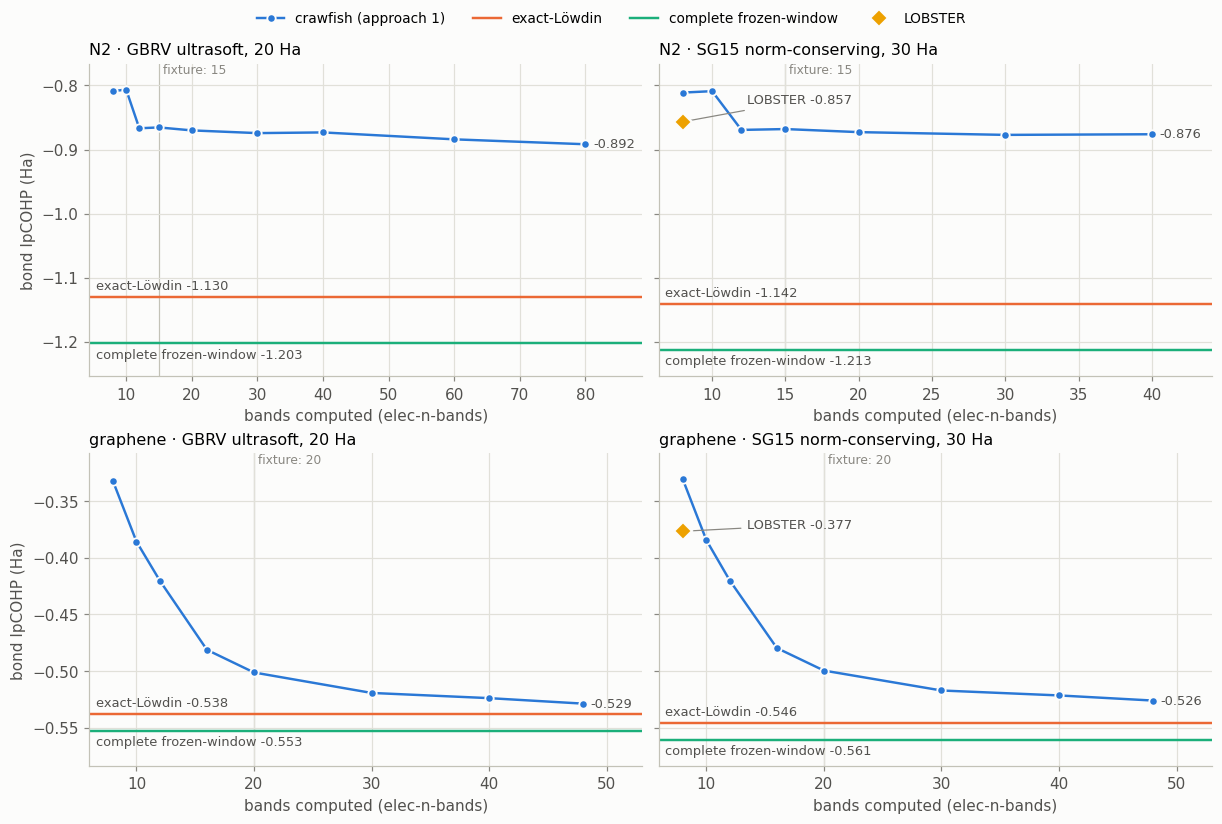

In [6]:
def panel_grid():
    fig, axes = plt.subplots(2, 2, figsize=(11, 7.4), sharey="row", constrained_layout=True)
    fig.patch.set_facecolor(bm.SURFACE)
    for ax, (name, s) in zip(axes.flat, SYSTEMS.items()):
        bm.style_axes(ax)
        ax.set_title(f"{s.molecule} · {s.psp}", loc="left")
        ax.axvline(s.nbands_fixture, color=bm.AXIS, linewidth=0.8, zorder=0)
        ax.text(s.nbands_fixture, 1.0, f" fixture: {s.nbands_fixture}", transform=ax.get_xaxis_transform(),
                ha="left", va="top", fontsize=8, color=bm.MUTED)
        ax.set_xlabel("bands computed (elec-n-bands)")
    for ax in axes[:, 0]:
        ax.set_ylabel("bond IpCOHP (Ha)")
    return fig, axes


def plot_series(ax, data, key, label=None, color=None, marker="o", linestyle="-", end_label=True):
    nbs = sorted(data)
    vals = [data[nb] for nb in nbs]
    ax.plot(nbs, vals, color=color or bm.COLORS[key], linestyle=linestyle, linewidth=1.6, marker=marker,
            markersize=5.5, markeredgecolor=bm.SURFACE, markeredgewidth=1.2, label=label or key, zorder=3)
    if end_label:
        ax.annotate(f"{vals[-1]:+.3f}", (nbs[-1], vals[-1]), xytext=(5, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=bm.INK2)


def plot_limit(ax, value, key, above=True):
    ax.axhline(value, color=bm.COLORS[key], linewidth=1.6, label=key, zorder=2)
    ax.annotate(f"{key} {value:+.3f}", (0.0, value), xycoords=("axes fraction", "data"),
                xytext=(4, 3 if above else -3), textcoords="offset points", ha="left",
                va="bottom" if above else "top", fontsize=8.5, color=bm.INK2)


def plot_marker(ax, nb, value, key, legend_label=None, marker="D", text=None, offset=(42, 14)):
    """A single value; `text` is placed at `offset` points with a leader line, clear of the curves."""
    ax.plot([nb], [value], linestyle="none", marker=marker, markersize=8, color=bm.COLORS[key],
            markeredgecolor=bm.SURFACE, markeredgewidth=1.5, label=legend_label or key, zorder=4)
    if text:
        ax.annotate(f"{text} {value:+.3f}", (nb, value), xytext=offset, textcoords="offset points", va="center",
                    fontsize=8.5, color=bm.INK2,
                    arrowprops=dict(arrowstyle="-", color=bm.MUTED, linewidth=0.8, shrinkA=2, shrinkB=5))


def finish(fig, axes, path):
    handles, labels = {}, {}
    for ax in axes.flat:
        for h, l in zip(*ax.get_legend_handles_labels()):
            handles.setdefault(l, h)
    fig.legend(handles.values(), handles.keys(), loc="outside upper center", ncols=3 if len(handles) > 4 else 4,
               frameon=False)
    for ax in axes.flat:
        ax.set_xlim(right=ax.get_xlim()[1] * 1.06)
    fig.savefig(path, dpi=150, facecolor=bm.SURFACE)
    plt.show()


fig, axes = panel_grid()
for ax, name in zip(axes.flat, SYSTEMS):
    plot_series(ax, series[name]["crawfish"], "crawfish", "crawfish (approach 1)")
    plot_limit(ax, limits[name]["exact-Löwdin"], "exact-Löwdin", above=True)
    plot_limit(ax, limits[name]["complete frozen-window"], "complete frozen-window", above=False)
    if "LOBSTER" in limits[name]:
        plot_marker(ax, 8, limits[name]["LOBSTER"], "LOBSTER", text="LOBSTER",
                    offset=(42, 14) if name.startswith("N2") else (42, 4))
finish(fig, axes, bm.FIGURE_DIR / "01_crawfish_vs_limits.png")

**Reading figure 1.**
- **N2 never converges in practice.** From 12 to 80 bands, crawfish's N2 IpCOHP only creeps from −0.87 to
  −0.89 Ha (GBRV), while its own limit is −1.13 Ha (GBRV) or −1.14 Ha (SG15). The 15-band fixture setting is 23%
  short. The missing bands are box (vacuum) states, and there is no end to them. Below 12 bands the lowest bands
  miss σ* entirely: that is the dropped direction and energy-zero effect of section 1.
- **Graphene converges, slowly.** The fixture's 20 bands are 7% short of exact-Löwdin and 48 bands are 2% short.
  Up to 20 bands the basis is ill-conditioned at some k-points, and crawfish's too-few-bands warning fires. The
  warning does not catch the slow part of the convergence.
- **LOBSTER is approach 1 at 8 bands** (pure polar factor, absolute energies; section 4). It is not a reference
  for the converged value. Where it sits relative to crawfish's first point depends on the dropped direction:
  crawfish's 8-band N2 value is the energy-zero-shifted one discussed in section 1.
- **The two limits differ by 6% (N2) and 3% (graphene).** That is the effect of letting the basis adapt to the
  occupied states (section 3) rather than keeping the shape of the free-atom orbitals (section 2).
- **The pseudopotential barely matters.** GBRV and SG15 agree within 1–1.5% at every point and converge the same
  way.

## 5. Frozen-window projected Wannier functions in band space

This is section 3's construction using only the computed bands, with no exact atomic-orbital matrices. It is what
JDFTx's `wannier` does with `wannier-minimize nIterations 0` (`WannierMinimizer::initRotations`). At each state,
with $A_{j\mu}=\langle\psi_j|\hat O|g_\mu\rangle$ for $j\le n_b$:

1. **Windows.** The frozen bands $F$ are chosen as in section 3. The other computed bands, $P$, form the outer
   window.
2. **Best virtual combinations.** $V_{\rm free}$ holds the trial combinations the frozen bands leave uncovered:
   the right singular vectors of $A_F$ beyond its rank $n_F$. They are matched by the $n_W-n_F$ orthonormal
   combinations of outer bands that overlap them best,
   $|\psi'_\alpha\rangle=\sum_{j\in P}|\psi_j\rangle\big[B(B^\dagger B)^{-1/2}\big]_{j\alpha}$, with
   $B=A_PV_{\rm free}$.
3. **Basis functions.** $W=\mathrm{span}\{\psi_j\}_{j\in F}\oplus\mathrm{span}\{\psi'_\alpha\}$. The basis
   functions are the trial orbitals projected into $W$ and Löwdin-orthonormalized there (step 4 of section 3),
   and $H$ is the band sum over $W$.

**How this differs from crawfish's basis.** Both build orthonormal orbitals from the same projections. The
difference is the space those orbitals span:
- crawfish's $\chi_\mu$ are the trial orbitals projected onto all $n_b$ bands. The occupied bands are then only
  partly inside their span (charge spilling > 0), and every computed band contributes in proportion to its overlap
  with the orbitals.
- The frozen-window basis spans an $n_W$-dimensional space that contains the occupied bands exactly, plus only the
  virtual combinations that best complete the orbitals. Spilling is zero and the sum rule is exact at every $n_b$.

As $n_b\to\infty$, the $\psi'_\alpha$ converge to the $f_\alpha$ of section 3 ($A_FV_{\rm free}=0$, so the $g$
combinations they target are already orthogonal to the frozen bands). Section 3 is therefore this basis's
complete limit.

Here the trial orbitals are the Löwdin orbitals (orthonormalized-orbital projections), as in section 3. JDFTx's
`addAtomicOrbitals` uses the bare orbitals $\phi_\mu$, which changes N2 by about 1% (notes 10.4).

## 6. Projectability-disentangled FW-PWF (PDWF)

Qiao, Pizzi and Marzari (npj Comput. Mater. 9, 208 (2023)) choose the windows by each band's projectability
$p_j(t)=\sum_\mu|\langle\tilde\phi_\mu|\hat O|\psi_j(t)\rangle|^2$, not by energy alone:
- bands with $p_j\le p_{\min}$ leave the outer window, since they carry no orbital character (vacuum states, for
  example);
- bands with $p_j>p_{\max}$ are frozen, in addition to the energy window.

JDFTx offers this as `projectionThresholds` in its `wannier` command. Here $p_{\min}=0.01$ and $p_{\max}=0.95$.
PDWF needs at least $n_W$ bands with $p_j>p_{\min}$, so it is undefined for N2 at 8 bands: band 8 has $p=0.002$.

## 7. JDFTx `wannier`: projection-only and maximally localized

The GBRV folders hold two JDFTx `wannier` runs. Both put all bands in the outer window and use
`addAtomicOrbitals yes` (the bare-orbital trial):
- `wproj_*`, with `wannier-minimize nIterations 0`: approach 5 with the bare-orbital trial, computed by JDFTx;
- `wmlwf_pin`, with `nIterations 1000` and `pinAtomicOrbitals yes`, which also minimizes the total spread
  $\Omega=\sum_\mu\left[\langle w_\mu|r^2|w_\mu\rangle-|\langle w_\mu|\mathbf r|w_\mu\rangle|^2\right]$ over
  unitary rotations within the subspace.

JDFTx writes the Wannier Hamiltonian $H_{\mu\nu}(R)$. It is interpolated back onto the DFT k-mesh,
$H(k)=\sum_Re^{2\pi ik\cdot R}H(R)$, and its eigenvectors play the role of $C$. For N2, spread minimization turns
the σ functions into hybrids that no longer couple across the bond. The σ part of the pair IpCOHP vanishes, while
π is unchanged.

In [7]:
for name, s in SYSTEMS.items():
    co = calc[name]["ortho"]
    for key, kw in (("frozen-window PWF", {}),
                    ("PDWF", dict(p_min=0.01, p_max=0.95, projectability_tj=co.projectability_tj))):
        series[name][key] = {}
        for nb in s.nbands_series:
            try:
                series[name][key][nb] = bm.bond_icohp(bm.frozen_window_pwf(co, s.e_frozen, nb, **kw), co)
            except ValueError as err:  # the computed bands cannot hold n_W orbital-like functions
                print(f"{key} undefined for {name} at {nb} bands: {err}")
    for run in s.wannier_runs:
        limits[name]["MLWF" if run.startswith("wmlwf") else "JDFTx projection-only"] = \
            bm.bond_icohp(bm.jdftx_wannier(co, run), co)
for key in ("frozen-window PWF", "PDWF"):
    print(key)
    display(pd.DataFrame({name: series[name][key] for name in SYSTEMS}).sort_index().rename_axis("bands"))
display(pd.DataFrame({k: v for k, v in limits.items()}).T[["JDFTx projection-only", "MLWF"]].dropna())

PDWF undefined for N2_gbrv at 8 bands: state 0: 7 frozen and 0 other bands for 8 functions
PDWF undefined for N2_gbrv at 10 bands: state 0: 7 frozen and 0 other bands for 8 functions
PDWF undefined for N2_sg15 at 8 bands: state 0: 7 frozen and 0 other bands for 8 functions
PDWF undefined for N2_sg15 at 10 bands: state 0: 7 frozen and 0 other bands for 8 functions
frozen-window PWF undefined for graphene_gbrv at 8 bands: state 0: the trial orbitals do not cover the subspace (too little orbital character in the non-frozen bands)
frozen-window PWF undefined for graphene_gbrv at 10 bands: state 0: the trial orbitals do not cover the subspace (too little orbital character in the non-frozen bands)
frozen-window PWF undefined for graphene_gbrv at 12 bands: state 0: the trial orbitals do not cover the subspace (too little orbital character in the non-frozen bands)
frozen-window PWF undefined for graphene_gbrv at 16 bands: state 6: the trial orbitals do not cover the subspace (too little orbita

,N2_gbrv,N2_sg15,graphene_gbrv,graphene_sg15
bands,,,,
8,-0.8548,-0.8580,NaN,NaN
10,-0.8701,-0.8696,NaN,NaN
12,-0.8713,-0.8735,NaN,NaN
15,-0.8713,-0.8735,NaN,NaN
20,-0.8787,-0.8810,NaN,-0.5110
30,-0.8840,-0.8864,-0.5317,-0.5295
40,-0.8883,-0.8906,-0.5370,-0.5346
48,NaN,NaN,-0.5423,-0.5396
60,-0.9031,NaN,NaN,NaN


PDWF


,N2_gbrv,N2_sg15,graphene_gbrv,graphene_sg15
bands,,,,
12,-0.8713,-0.8735,NaN,NaN
15,-0.8713,-0.8735,NaN,NaN
20,-0.8784,-0.8806,NaN,NaN
30,-0.8833,-0.8857,-0.5289,-0.5267
40,-0.8833,-0.8857,-0.5313,-0.5292
48,NaN,NaN,-0.5345,-0.5322
60,-0.8970,NaN,NaN,NaN
80,-0.9061,NaN,NaN,NaN


,JDFTx projection-only,MLWF
N2_gbrv,-0.9259,-0.3636
graphene_gbrv,-0.5423,-0.5193


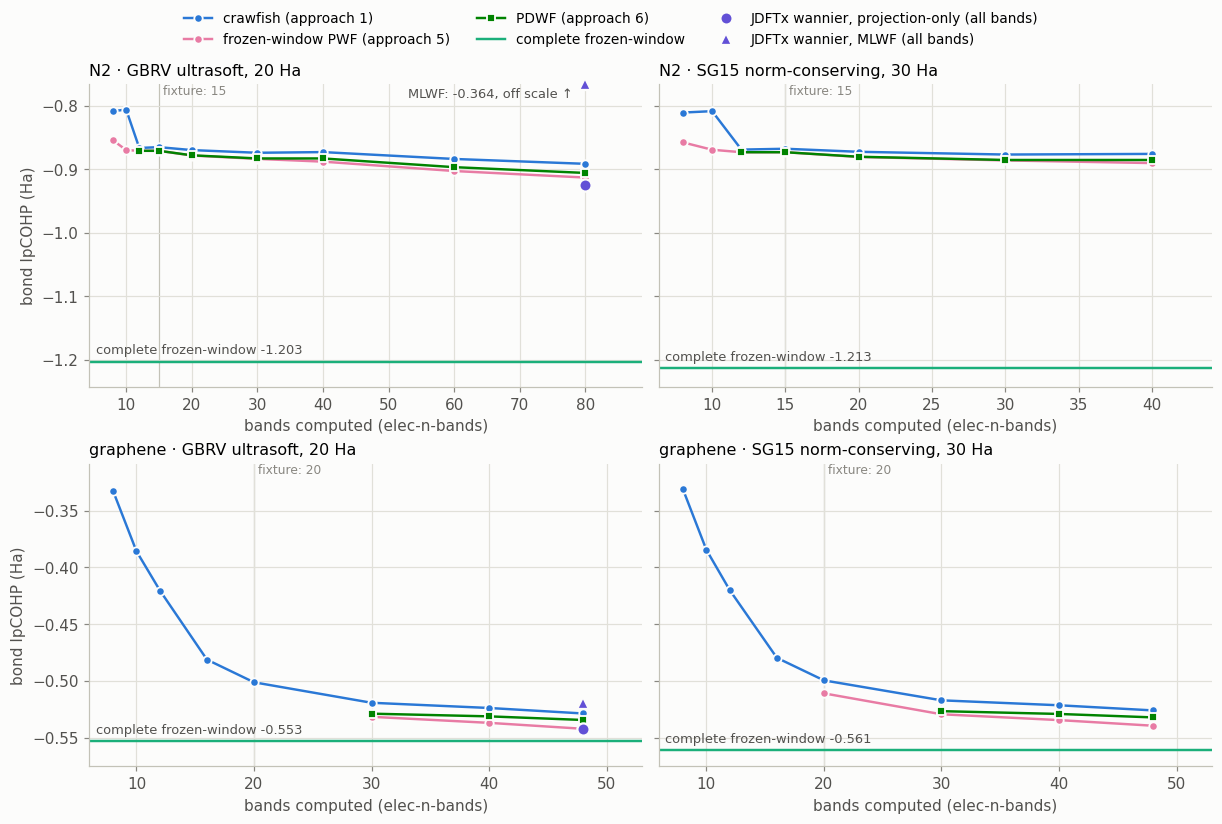

In [8]:
fig, axes = panel_grid()
for ax, (name, s) in zip(axes.flat, SYSTEMS.items()):
    # the lines converge at the right edge, so identity comes from the legend (no end labels)
    plot_series(ax, series[name]["crawfish"], "crawfish", "crawfish (approach 1)", end_label=False)
    plot_series(ax, series[name]["frozen-window PWF"], "frozen-window PWF", "frozen-window PWF (approach 5)",
                end_label=False)
    plot_series(ax, series[name]["PDWF"], "PDWF", "PDWF (approach 6)", marker="s", end_label=False)
    plot_limit(ax, limits[name]["complete frozen-window"], "complete frozen-window", above=True)
    nb_all = s.nbands_series[-1]
    if "JDFTx projection-only" in limits[name]:
        plot_marker(ax, nb_all, limits[name]["JDFTx projection-only"], "JDFTx wannier",
                    "JDFTx wannier, projection-only (all bands)", marker="o")
    if "MLWF" in limits[name]:
        v = limits[name]["MLWF"]
        lo, hi = ax.get_ylim()
        if v > hi:  # N2: far above the other values; marked at the top edge with its value
            ax.plot([nb_all], [hi], linestyle="none", marker="^", markersize=8, color=bm.COLORS["JDFTx wannier"],
                    markeredgecolor=bm.SURFACE, markeredgewidth=1.5, clip_on=False, zorder=4,
                    label="JDFTx wannier, MLWF (all bands)")
            ax.annotate(f"MLWF: {v:+.3f}, off scale ↑", (nb_all, hi), xytext=(-8, -2), textcoords="offset points",
                        ha="right", va="top", fontsize=8.5, color=bm.INK2)
            ax.set_ylim(lo, hi)
        else:
            plot_marker(ax, nb_all, v, "JDFTx wannier", "JDFTx wannier, MLWF (all bands)", marker="^")
finish(fig, axes, bm.FIGURE_DIR / "01_wannier_type_bases.png")

**Reading figure 2.**
- **Zero spilling does not mean convergence.** The band-space frozen-window basis has zero spilling and an exact
  sum rule at every band count. Its N2 value still converges as slowly as crawfish's, because the virtual
  directions it needs are the same box states. At all bands it is about 2% stronger than crawfish, and the gap to
  its complete limit (horizontal line) is what the missing bands cost.
- **Graphene converges better.** With 48 bands the band-space basis is 2% (GBRV) and 4% (SG15) from its complete
  limit.
- **The band-space basis needs enough bands to exist.** In graphene it is undefined below 20–30 bands: the
  non-frozen bands then carry too little orbital character to complete the basis (the cell above lists where).
- **PDWF thresholds change little here.** PDWF is within 1.5% of the plain frozen window wherever both are defined,
  and it needs a few more bands. The thresholds matter most when weakly projecting bands sit inside the energy
  window.
- **JDFTx's projection-only `wannier` agrees with approach 5.** It uses the bare-orbital trial and is within 1.4%
  of approach 5 (Löwdin trial) for N2, and identical for graphene.
- **Spread minimization destroys the σ bond of N2** (MLWF, off scale). In graphene it stays within 5% of the
  projection-only value. Don't use maximally localized functions for atom-pair COHP.

## 8. Projection type and pseudopotential

crawfish's Löwdin step (approach 1) can also take non-orthogonal projections (`band-projection-params no no`). The
trial orbitals are then the bare $\phi_\mu$ instead of $\tilde\phi_\mu$:
- **In the complete limit the two agree.** Löwdin orthonormalization of $\phi$ gives $\tilde\phi$.
- **At finite $n_b$ they differ.** The band-space Löwdin step is not invariant under the non-unitary mixing
  $\tilde\phi=\phi S^{-1/2}$.
- **Ultrasoft pseudopotentials add a second problem.** In its non-orthogonal branch, released JDFTx applies only
  the single-centre part of $\hat O$ to $\phi$ (`OpsiRadial`; notes 10.3, `notes/theory_audit.md` F13). Those
  projections are slightly wrong and converge to a different limit. The patched `fullO` field applies the full
  operator.
- **Norm-conserving pseudopotentials can't have it.** They have $\hat O=1$.

(This section is about pCOHP with `los_orbs=True`. pCOOP needs non-orthogonal projections with `los_orbs=False`;
see the README.)

In [9]:
for name, s in SYSTEMS.items():
    series[name]["crawfish, non-ortho (full O)"] = {nb: bm.crawfish_ipcohp(name, nb, "nonortho")[0]
                                                   for nb in s.nbands_series}
    if (bm.DATA_DIR / name / "nonortho.bandProjections").exists():
        series[name]["crawfish, non-ortho (JDFTx)"] = {nb: bm.crawfish_ipcohp(name, nb, "nonortho_jdftx")[0]
                                                      for nb in s.nbands_series}
keys = ["crawfish", "crawfish, non-ortho (full O)", "crawfish, non-ortho (JDFTx)"]
display(pd.concat({name: pd.DataFrame({k: series[name][k] for k in keys if k in series[name]})
                   for name in SYSTEMS}, axis=1).sort_index().rename_axis("bands"))

N2_gbrv                                                           \
      crawfish crawfish, non-ortho (full O) crawfish, non-ortho (JDFTx)   
bands                                                                     
8      -0.8088                      -0.8272                     -0.8303   
10     -0.8064                      -0.8251                     -0.8284   
12     -0.8668                      -0.8832                     -0.8877   
15     -0.8655                      -0.8819                     -0.8863   
16         NaN                          NaN                         NaN   
20     -0.8701                      -0.8855                     -0.8906   
30     -0.8744                      -0.8893                     -0.8944   
40     -0.8733                      -0.8883                     -0.8935   
48         NaN                          NaN                         NaN   
60     -0.8841                      -0.8982                     -0.9035   
80     -0.8918                      -0.9053                     -0.9111   

       N2_sg15                                                           \
      crawfish crawfish, non-ortho (full O) crawfish, non-ortho (JDFTx)   
bands                                                                     
8      -0.8111                      -0.8283                     -0.8283   
10     -0.8089                      -0.8264                     -0.8264   
12     -0.8694                      -0.8850                     -0.8850   
15     -0.8681                      -0.8836                     -0.8836   
16         NaN                          NaN                         NaN   
20     -0.8728                      -0.8875                     -0.8875   
30     -0.8772                      -0.8914                     -0.8914   
40     -0.8762                      -0.8905                     -0.8905   
48         NaN                          NaN                         NaN   
60         NaN                          NaN                         NaN   
80         NaN                          NaN                         NaN   

      graphene_gbrv                                                           \
           crawfish crawfish, non-ortho (full O) crawfish, non-ortho (JDFTx)   
bands                                                                          
8           -0.3323                      -0.3250                     -0.3197   
10          -0.3857                      -0.3761                     -0.3601   
12          -0.4204                      -0.4150                     -0.4105   
15              NaN                          NaN                         NaN   
16          -0.4813                      -0.4796                     -0.4740   
20          -0.5013                      -0.5006                     -0.4948   
30          -0.5193                      -0.5191                     -0.5123   
40          -0.5239                      -0.5237                     -0.5165   
48          -0.5288                      -0.5287                     -0.5209   
60              NaN                          NaN                         NaN   
80              NaN                          NaN                         NaN   

      graphene_sg15                               
           crawfish crawfish, non-ortho (full O)  
bands                                             
8           -0.3309                      -0.3233  
10          -0.3845                      -0.3693  
12          -0.4202                      -0.4180  
15              NaN                          NaN  
16          -0.4797                      -0.4780  
20          -0.4996                      -0.4989  
30          -0.5172                      -0.5169  
40          -0.5215                      -0.5213  
48          -0.5261                      -0.5259  
60              NaN                          NaN  
80              NaN                          NaN

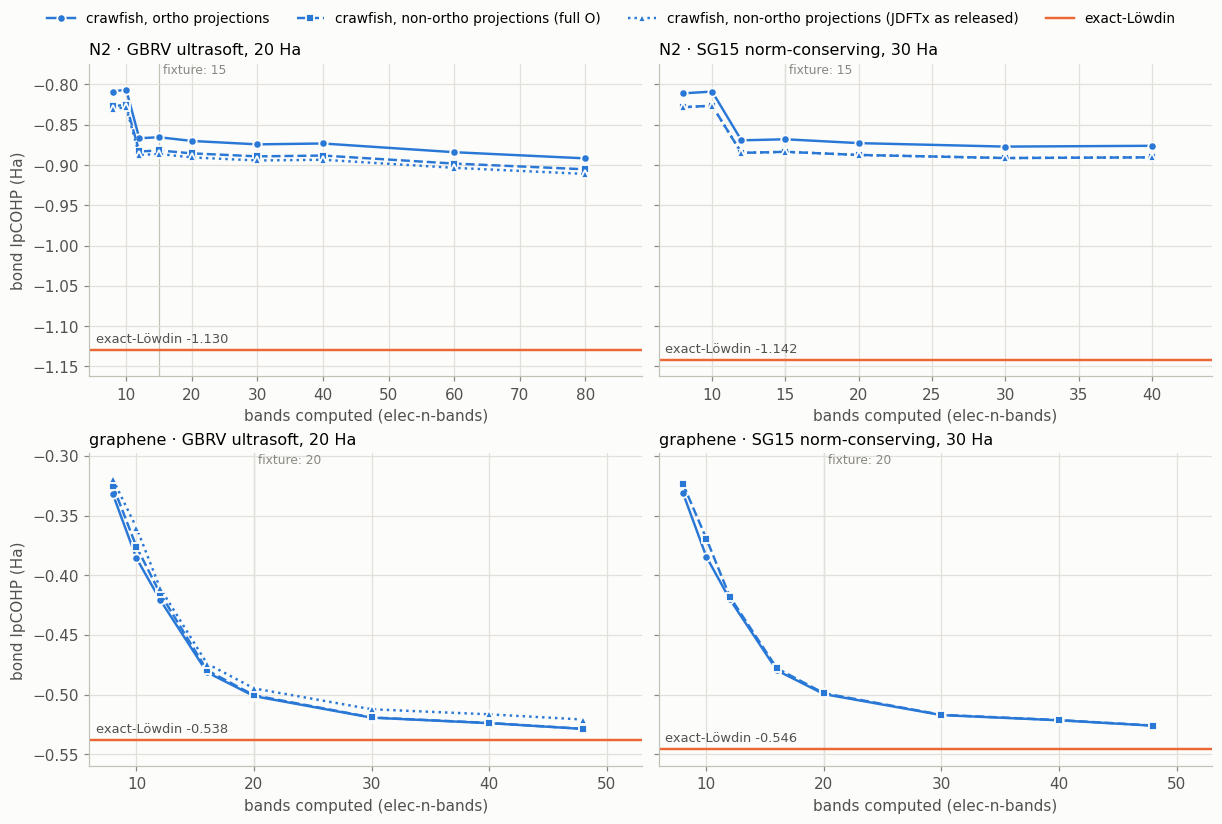

In [10]:
fig, axes = panel_grid()
variants = {"crawfish": ("crawfish, ortho projections", "o", "-"),
            "crawfish, non-ortho (full O)": ("crawfish, non-ortho projections (full O)", "s", "--"),
            "crawfish, non-ortho (JDFTx)": ("crawfish, non-ortho projections (JDFTx as released)", "^", ":")}
for ax, name in zip(axes.flat, SYSTEMS):
    for key, (label, marker, ls) in variants.items():
        if key in series[name]:
            plot_series(ax, series[name][key], "crawfish", label, marker=marker, linestyle=ls, end_label=False)
    plot_limit(ax, limits[name]["exact-Löwdin"], "exact-Löwdin", above=True)
finish(fig, axes, bm.FIGURE_DIR / "01_projection_type.png")

**Reading figure 3.**
- **Finite-$n_b$ values depend on the projection type.** Ortho and full-O non-ortho projections differ by 1.5–2%
  at every band count for N2, and by less than 0.5% from 20 bands on for graphene. Both converge to the
  exact-Löwdin limit as $n_b\to\infty$ (section 2). Fix the projection type when comparing bonds.
- **For ultrasoft pseudopotentials, released JDFTx's non-orthogonal projections differ again.** They differ from
  the full-O ones by 0.6% for N2, and for graphene by up to 4% at small band counts and 1.5% at 48 bands. For pCOHP
  use `band-projection-params yes no` (the default recommendation); for USPP pCOOP keep the caveat of
  `notes/theory_audit.md` F13 in mind.
- **For SG15 ($\hat O=1$) the two non-orthogonal dumps are the same,** and so are the curves.
- **Across columns, GBRV vs SG15 changes the curves by ≤ 1.5%.** Changing the pseudopotential family does not fix
  the band convergence.

## 9. Where the missing bond strength is: σ and π in N2

The N2 bond splits into σ (s–s, s–px + px–s, px–px; the bond is along x) and π (py–py + pz–pz).

,crawfish 8,crawfish 15,crawfish 80,exact-Löwdin,complete frozen-window
σ s–s,-0.1032,-0.1110,-0.1161,-0.1699,-0.1681
σ s–px,-0.2495,-0.2795,-0.2965,-0.4244,-0.4329
σ px–px,-0.0954,-0.1181,-0.1251,-0.1847,-0.2261
π,-0.3608,-0.3570,-0.3540,-0.3508,-0.3758


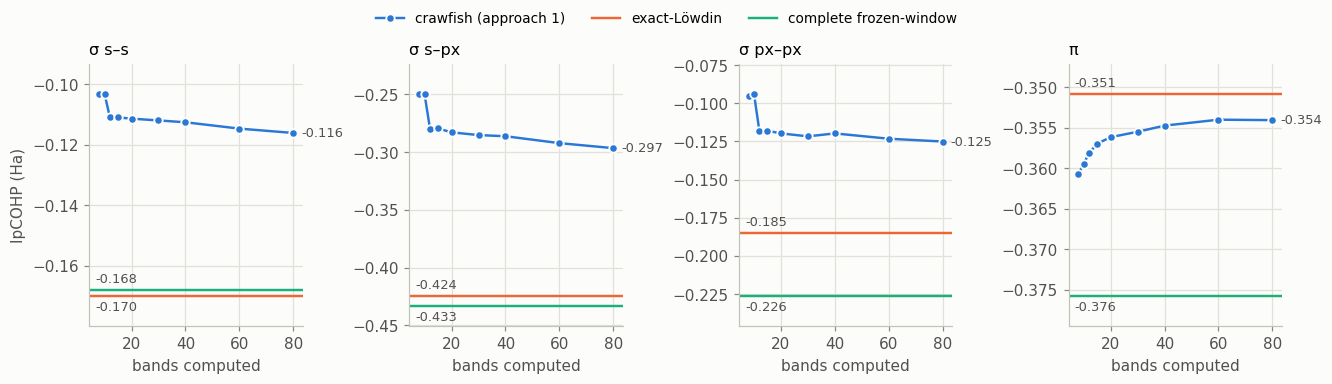

In [11]:
name = "N2_gbrv"
co, cn = calc[name]["ortho"], calc[name]["nonortho"]
S, H = ao[name]
nbs = SYSTEMS[name].nbands_series
crawfish_ch = {nb: bm.n2_channels(bm.crawfish_basis(co, nb), co) for nb in nbs}
exact_ch = bm.n2_channels(bm.exact_lowdin(co, S, H), co)
fw_ch = bm.n2_channels(bm.complete_frozen_window(cn, S, H, SYSTEMS[name].e_frozen), co)
display(pd.DataFrame({**{f"crawfish {nb}": crawfish_ch[nb] for nb in (8, 15, 80)},
                      "exact-Löwdin": exact_ch, "complete frozen-window": fw_ch}))

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), constrained_layout=True)
fig.patch.set_facecolor(bm.SURFACE)
for ax, ch in zip(axes, exact_ch):
    bm.style_axes(ax)
    ax.margins(y=0.15)  # room for the limit labels in these narrow panels
    ax.set_title(ch, loc="left")
    ax.set_xlabel("bands computed")
    plot_series(ax, {nb: crawfish_ch[nb][ch] for nb in nbs}, "crawfish", "crawfish (approach 1)")
    plot_limit(ax, exact_ch[ch], "exact-Löwdin", above=exact_ch[ch] > fw_ch[ch])
    plot_limit(ax, fw_ch[ch], "complete frozen-window", above=fw_ch[ch] >= exact_ch[ch])
    for txt in ax.texts[1:]:  # keep the limit labels short in these narrow panels
        txt.set_text(txt.get_text().split()[-1])
axes[0].set_ylabel("IpCOHP (Ha)")
handles = dict(zip(*reversed(axes[0].get_legend_handles_labels())))
fig.legend(handles.values(), handles.keys(), loc="outside upper center", ncols=3, frameon=False)
fig.savefig(bm.FIGURE_DIR / "01_n2_sigma_pi.png", dpi=150, facecolor=bm.SURFACE)
plt.show()

**Reading figure 4.**
- **π is converged.** By 15 bands it is within 2% of exact-Löwdin and 5% of the complete frozen-window value.
- **σ is not.** The whole shortfall is in σ, mostly s–px: −0.30 Ha at 80 bands against −0.42 Ha in either limit.
  The σ* combination of s and px is spread over many box states, so no practical band count captures it.

## 10. Spectra: which peaks grow and shrink

The IpCOHP values above are integrals. The spectrum behind them shows which states the band count and the
setup change. For the bond (all orbitals of atom 1 with all orbitals of atom 2's image $R$, averaged over the
equivalent bonds):

$$
\mathrm{pCOHP}(E)=\sum_{\mu,\nu}\sum_{t,j}w_t\,Re\left[C^*_{\mu,j}\,H_{\mu\nu}(R)\,e^{2\pi ik_t\cdot R}\,C_{\nu,j}\right]
\delta\big(E-\epsilon_j(t)\big),\qquad
\mathrm{IpCOHP}=\int\mathrm{pCOHP}(E)\,f(E)\,dE .
$$

The δ is broadened to a Gaussian with a standard deviation of 0.01 Ha (crawfish's `sig` is $2\sigma^2$, so
`get_pcohp(..., sig=2e-4)`). The plots show −pCOHP, so bonding is up, against $E-\mu$ in Ha.

What the rows $j$ are:
- **crawfish and the band-space frozen window:** the computed bands. crawfish's curves come from its own
  `get_pcohp` on the truncated files.
- **exact-Löwdin:** also the computed bands. Its coefficients are exact band by band, but its spectrum stops at
  the highest computed band. That region is shaded gray for N2; graphene's 48 bands reach past the plotted window.
- **complete frozen-window and JDFTx `wannier`:** the eigenstates of the basis Hamiltonian within the span of the
  basis, $\sum_\nu H_{\mu\nu}U_{\nu n}=\varepsilon_nU_{\mu n}$, with $C_{\mu,n}=U_{\mu n}$. In the frozen window
  these are the DFT bands themselves. Above it the energies are Ritz values (`benchmark.ritz_states`).

**A sum rule to read them by.** In crawfish's basis $\sum_{j\le n_b}C_{\mu,j}C^*_{\nu,j}=\delta_{\mu\nu}$ at
every state (section 1). For orbitals on two different atoms, the pCOHP weights of all computed bands therefore
add up to zero:

$$
\sum_t\sum_{j\le n_b}w_t\,Re\left[C^*_{\mu,j}H_{\mu\nu}(R)e^{2\pi ik_t\cdot R}C_{\nu,j}\right]
=\sum_tw_t\,Re\left[H_{\mu\nu}(R)e^{2\pi ik_t\cdot R}\,\delta_{\mu\nu}\right]=0 .
$$

Every bonding peak below μ is balanced by antibonding weight in the same $n_b$ bands. The bonding weight of the
occupied bands equals the antibonding weight of the computed empty bands.
- **The complete frozen-window basis** obeys the same rule over its $n_W$ states.
- **Exact-Löwdin** obeys it only over all bands, including those never computed.
- **The rule fails where the Löwdin step dropped a direction** (N2 at 8 and 10 bands, section 1).

In [12]:
SPEC = {"N2": dict(window=(-1.0, 0.85), nbs=(8, 10, 12, 15, 30, 80)),
        "graphene": dict(window=(-0.78, 0.8), nbs=(8, 12, 16, 20, 30, 48))}
STD = 0.01  # Ha: Gaussian standard deviation (crawfish's sig = 2 * STD**2)
spectra = {}  # spectra[system][approach] = pCOHP on spectra[system]["x"] (= E - mu); per band count: {nb: pCOHP}
for name, s in SYSTEMS.items():
    co, cn = calc[name]["ortho"], calc[name]["nonortho"]
    S, H = ao[name]
    lo, hi = SPEC[s.molecule]["window"]
    er = co.mu + np.arange(lo, hi + 5e-4, 1e-3)  # absolute Ha, as crawfish takes it
    nbs = [nb for nb in SPEC[s.molecule]["nbs"] if nb <= co.nbands]
    sp = spectra[name] = {"x": er - co.mu, "top": co.e_tj[:, -1].min() - co.mu}  # top: highest band at every k
    for proj in ("ortho", "nonortho", "nonortho_jdftx"):
        if (bm.DATA_DIR / name / f"{bm.PROJECTIONS[proj][0]}.bandProjections").exists():
            key = "crawfish" if proj == "ortho" else f"crawfish, {proj}"
            sp[key] = {nb: bm.crawfish_pcohp(name, nb, er, STD, proj) for nb in nbs}
    for nb in nbs:  # crawfish against the float64 implementation (section 1), at the absolute band energies
        ref = bm.gauss_spectrum(co.e_tj[:, :nb], bm.bond_weights_tj(bm.crawfish_basis(co, nb), co), er, STD)
        assert np.abs(sp["crawfish"][nb] - ref).max() < 1e-3 * np.abs(ref).max(), (name, nb)
    for key, kw in (("frozen-window PWF", {}),
                    ("PDWF", dict(p_min=0.01, p_max=0.95, projectability_tj=co.projectability_tj))):
        sp[key] = {}
        for nb in nbs:
            try:
                sp[key][nb] = bm.bond_pcohp(bm.frozen_window_pwf(co, s.e_frozen, nb, **kw), co, er, STD)
            except ValueError:  # undefined at this band count (section 5)
                pass
    sp["exact-Löwdin"] = bm.bond_pcohp(bm.exact_lowdin(co, S, H), co, er, STD)
    sp["complete frozen-window"] = bm.bond_pcohp(
        bm.ritz_states(bm.complete_frozen_window(cn, S, H, s.e_frozen), co), co, er, STD)
    for run in s.wannier_runs:
        sp["MLWF" if run.startswith("wmlwf") else "JDFTx projection-only"] = \
            bm.bond_pcohp(bm.jdftx_wannier(co, run), co, er, STD)
    if (bm.DATA_DIR / name / "lobster_custom").exists():  # LOBSTER, and approach 1 at its 8 bands without cutoff
        sp["LOBSTER"] = bm.lobster_bond_pcohp(name, er, STD)
        sp["polar factor, 8 bands"] = bm.bond_pcohp(bm.lowdin(co, 8, rtol=None), co, er, STD)


def rel(a, b):
    # largest difference of two spectra, over the largest peak of the second
    return np.abs(a - b).max() / np.abs(b).max()


print("PDWF against frozen-window PWF (largest difference / largest peak), where both are defined:")
display(pd.DataFrame({name: {nb: rel(sp["PDWF"][nb], sp["frozen-window PWF"][nb]) for nb in sp["PDWF"]}
                      for name, sp in spectra.items()}).sort_index().rename_axis("bands"))

PDWF against frozen-window PWF (largest difference / largest peak), where both are defined:


,N2_gbrv,N2_sg15,graphene_gbrv,graphene_sg15
bands,,,,
12,2.3744e-05,5.5154e-09,NaN,NaN
15,3.4071e-05,4.6632e-09,NaN,NaN
30,3.7179e-03,3.6176e-03,0.0073,0.0074
48,NaN,NaN,0.0164,0.0162
80,5.8712e-02,NaN,NaN,NaN


### Figure 5: spectra against the band count

Each panel overlays the spectra for several band counts, light to dark from fewer to more bands, with the
band-independent limit of the same basis dashed:
- rows 1–2: crawfish (approach 1) with the GBRV and SG15 pseudopotentials, against exact-Löwdin;
- row 3: frozen-window projected Wannier functions in band space (approach 5), against the complete
  frozen-window basis.

Every row uses the same light-to-dark order, in its approach's color. The y-axis is shared within each column.
PDWF (approach 6) is not drawn: where it is defined, it is within 6% (N2) and 2% (graphene) of approach 5 (table
above).

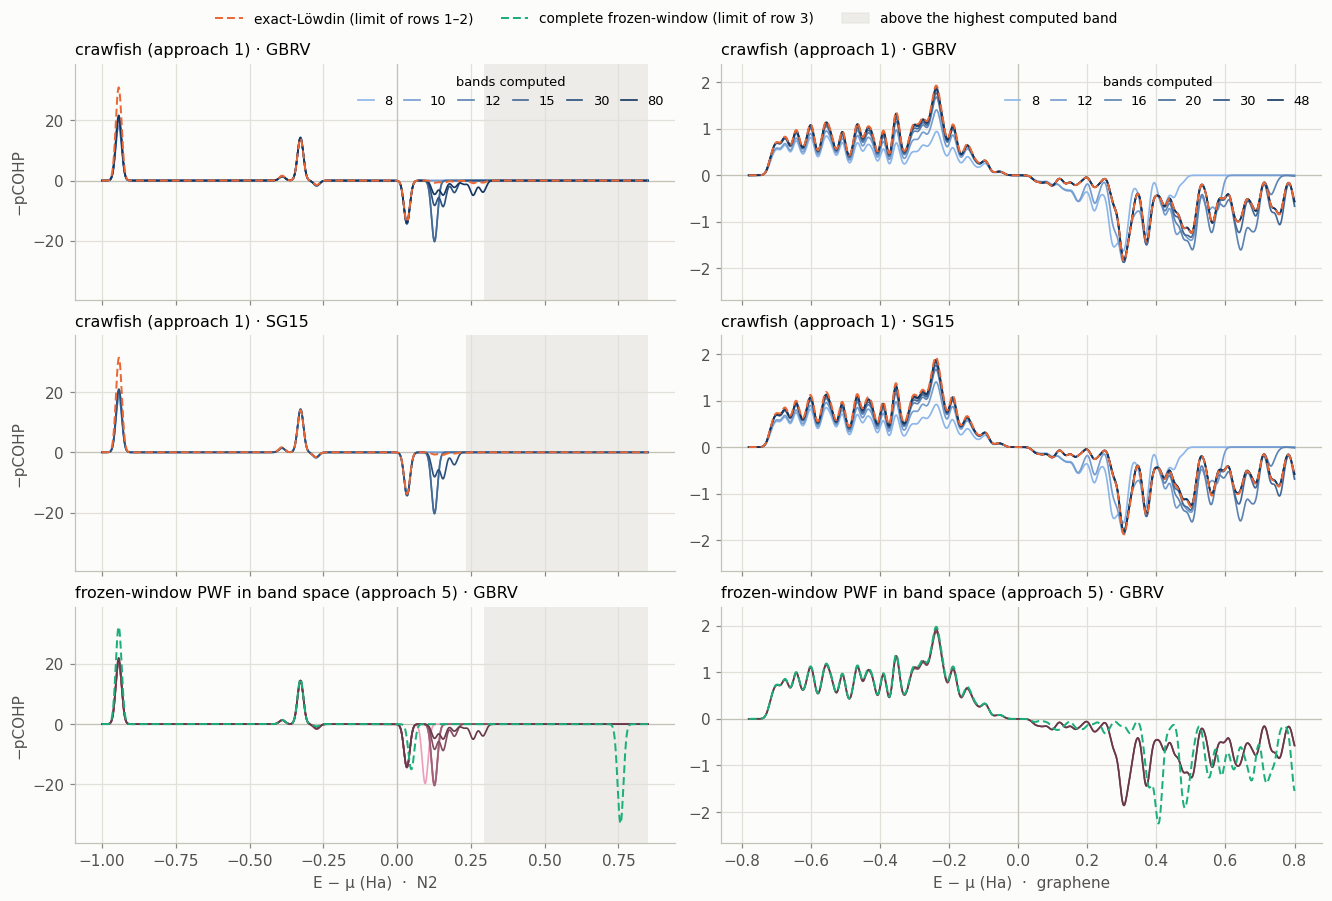

In [13]:
DASH = (0, (4, 2))


def spectrum_grid(nrows, height=2.1):
    """Rows of spectrum panels, N2 left and graphene right; x and y shared within a column."""
    fig, axes = plt.subplots(nrows, 2, figsize=(12, height * nrows + 0.9), sharex="col", sharey="col",
                             constrained_layout=True, squeeze=False)
    fig.patch.set_facecolor(bm.SURFACE)
    for ax in axes.flat:
        bm.style_axes(ax)
    for j, mol in enumerate(("N2", "graphene")):
        axes[-1, j].set_xlabel(f"E − μ (Ha)  ·  {mol}")
    for ax in axes[:, 0]:
        ax.set_ylabel("−pCOHP")
    return fig, axes


def spectrum_panel(ax, name, title):
    """Zero lines and the region above the highest computed band; returns the system's spectra."""
    sp = spectra[name]
    ax.axhline(0, color=bm.AXIS, linewidth=0.8, zorder=1)
    ax.axvline(0, color=bm.AXIS, linewidth=0.8, zorder=1)
    if sp["top"] < sp["x"][-1]:
        ax.axvspan(sp["top"], sp["x"][-1], color=bm.GRID, alpha=0.55, linewidth=0, zorder=0)
    ax.set_title(title, loc="left")
    return sp


def band_ramp(key, mol):
    """Color per band count: light to dark in the approach's color, the same for every row of a column."""
    return dict(zip(SPEC[mol]["nbs"], bm.ordinal_ramp(key, len(SPEC[mol]["nbs"]))))


ROWS5 = (("crawfish", "gbrv", "crawfish (approach 1) · GBRV", "exact-Löwdin"),
         ("crawfish", "sg15", "crawfish (approach 1) · SG15", "exact-Löwdin"),
         ("frozen-window PWF", "gbrv", "frozen-window PWF in band space (approach 5) · GBRV",
          "complete frozen-window"))
fig, axes = spectrum_grid(len(ROWS5), height=2.4)
for j, mol in enumerate(("N2", "graphene")):
    for i, (key, psp, title, ref) in enumerate(ROWS5):
        ax = axes[i, j]
        sp = spectrum_panel(ax, f"{mol}_{psp}", title)
        ramp = band_ramp(key, mol)
        for nb, y in sp[key].items():
            ax.plot(sp["x"], -y, color=ramp[nb], linewidth=1.1, zorder=2, label=str(nb))
        ax.plot(sp["x"], -sp[ref], color=bm.COLORS[ref], linewidth=1.3, linestyle=DASH, zorder=3)
    axes[0, j].legend(title="bands computed", ncols=len(SPEC[mol]["nbs"]), loc="upper right", frameon=False,
                      handlelength=1.2, columnspacing=0.9, fontsize=8.5, title_fontsize=8.5)
fig.legend(handles=[Line2D([], [], color=bm.COLORS["exact-Löwdin"], linestyle=DASH, linewidth=1.3,
                           label="exact-Löwdin (limit of rows 1–2)"),
                    Line2D([], [], color=bm.COLORS["complete frozen-window"], linestyle=DASH, linewidth=1.3,
                           label="complete frozen-window (limit of row 3)"),
                    Patch(color=bm.GRID, alpha=0.55, label="above the highest computed band")],
           loc="outside upper center", ncols=3, frameon=False)
fig.savefig(bm.FIGURE_DIR / "01_spectra_vs_bands.png", dpi=150, facecolor=bm.SURFACE)
plt.show()

The tables below give the area of each peak, i.e. the pCOHP weight $\sum w_t\,Re[\dots]$ (Ha, negative =
bonding) of the states under it:
- **N2 (Γ only):** per molecular level. The columns are crawfish at each band count, crawfish at the fixture's 15
  bands with non-orthogonal projections (figure 6), and the two limits. For the complete frozen-window basis,
  "higher empty states" is its single σ\* state.
- **Graphene:** the occupied weight is split into σ (s, px, py pairs) and π (pz–pz), and the empty weight into
  energy windows above μ. The non-orthogonal columns are at the fixture's 20 bands.

The last row of each table is the sum over all rows, which is the sum rule above.

In [14]:
def peak_bases(name):
    # (column, basis, row energies E - mu) for the peak tables
    s, co, cn = SYSTEMS[name], calc[name]["ortho"], calc[name]["nonortho"]
    S, H = ao[name]
    nbf = s.nbands_fixture
    cols = [(f"crawfish {nb}", bm.crawfish_basis(co, nb), co.e_tj[:, :nb] - co.mu) for nb in SPEC[s.molecule]["nbs"]]
    for label, c in (("non-ortho (full O)", cn), ("non-ortho (JDFTx)", bm.load(name, "nonortho_jdftx"))):
        cols.append((f"crawfish {nbf}, {label}", bm.crawfish_basis(c, nbf), co.e_tj[:, :nbf] - co.mu))
    ex = bm.exact_lowdin(co, S, H)
    fw = bm.ritz_states(bm.complete_frozen_window(cn, S, H, s.e_frozen), co)
    return cols + [("exact-Löwdin", ex, ex.e_tj - co.mu), ("complete frozen-window", fw, fw.e_tj - co.mu)]


N2_LEVELS = {"2σg": [0], "2σu": [1], "1πu": [2, 3], "3σg": [4], "1πg* (empty)": [5, 6],
             "higher empty states": slice(7, None)}
n2_peaks = {}
for label, b, e in peak_bases("N2_gbrv"):
    w = bm.bond_weights_tj(b, calc["N2_gbrv"]["ortho"]).sum(0)  # one state (Γ): one weight per row
    n2_peaks[label] = {**{lev: w[idx].sum() for lev, idx in N2_LEVELS.items()},
                       "occupied (= IpCOHP)": w[:5].sum(), "sum over the rows": w.sum()}
n2_peaks = pd.DataFrame(n2_peaks)
print("N2 · GBRV: pCOHP weight per level (Ha)")
display(n2_peaks.round(3) + 0.0)

EDGES = (0.0, 0.2, 0.4, 0.6, 0.8, np.inf)
co = calc["graphene_gbrv"]["ortho"]
gr_peaks = {}
for label, b, e in peak_bases("graphene_gbrv"):
    w = bm.bond_weights_tj(b, co)
    w_pi = bm.bond_weights_tj(b, co, [2], [6])  # pz-pz; by mirror symmetry pz couples to nothing else
    col = {"occupied σ": (b.occ_tj * (w - w_pi)).sum(), "occupied π (pz–pz)": (b.occ_tj * w_pi).sum()}
    for lo, hi in zip(EDGES[:-1], EDGES[1:]):
        window = f"empty, {lo:+.1f} to {hi:+.1f} Ha" if np.isfinite(hi) else f"empty, above {lo:+.1f} Ha"
        col[window] = ((1 - b.occ_tj) * w * ((e > lo) & (e <= hi))).sum()
    col["sum over the rows"] = w.sum()
    gr_peaks[label] = col
gr_peaks = pd.DataFrame(gr_peaks)
print("graphene · GBRV: pCOHP weight by channel (occupied) and by energy window (empty), Ha")
display(gr_peaks.round(3) + 0.0)

N2 · GBRV: pCOHP weight per level (Ha)


,crawfish 8,crawfish 10,crawfish 12,crawfish 15,crawfish 30,crawfish 80,"crawfish 15, non-ortho (full O)","crawfish 15, non-ortho (JDFTx)",exact-Löwdin,complete frozen-window
2σg,-0.458,-0.457,-0.515,-0.515,-0.525,-0.543,-0.527,-0.531,-0.776,-0.811
2σu,-0.035,-0.036,-0.034,-0.034,-0.034,-0.035,-0.051,-0.055,-0.040,-0.035
1πu,-0.361,-0.359,-0.358,-0.357,-0.355,-0.354,-0.357,-0.357,-0.351,-0.376
3σg,0.045,0.046,0.041,0.041,0.040,0.040,0.053,0.056,0.037,0.019
1πg* (empty),0.361,0.360,0.359,0.359,0.356,0.352,0.359,0.359,0.346,0.376
higher empty states,0.000,-0.001,0.508,0.507,0.518,0.540,0.523,0.528,0.090,0.827
occupied (= IpCOHP),-0.809,-0.806,-0.867,-0.866,-0.874,-0.892,-0.882,-0.886,-1.130,-1.203
sum over the rows,-0.448,-0.447,0.000,0.000,0.000,0.000,0.000,0.000,-0.694,0.000


graphene · GBRV: pCOHP weight by channel (occupied) and by energy window (empty), Ha


,crawfish 8,crawfish 12,crawfish 16,crawfish 20,crawfish 30,crawfish 48,"crawfish 20, non-ortho (full O)","crawfish 20, non-ortho (JDFTx)",exact-Löwdin,complete frozen-window
occupied σ,-0.286,-0.366,-0.426,-0.446,-0.463,-0.472,-0.445,-0.439,-0.481,-0.494
occupied π (pz–pz),-0.046,-0.055,-0.055,-0.055,-0.056,-0.057,-0.055,-0.055,-0.057,-0.060
"empty, +0.0 to +0.2 Ha",0.041,0.044,0.023,0.024,0.024,0.024,0.024,0.023,0.024,0.023
"empty, +0.2 to +0.4 Ha",0.167,0.174,0.142,0.142,0.138,0.138,0.142,0.140,0.139,0.066
"empty, +0.4 to +0.6 Ha",0.037,0.174,0.189,0.160,0.150,0.149,0.159,0.159,0.150,0.201
"empty, +0.6 to +0.8 Ha",0.000,0.000,0.122,0.125,0.106,0.106,0.124,0.122,0.106,0.164
"empty, above +0.8 Ha",0.000,0.000,0.001,0.049,0.103,0.113,0.049,0.047,0.114,0.100
sum over the rows,-0.087,-0.029,-0.005,-0.003,0.000,0.000,-0.003,-0.002,-0.005,0.000


**Reading figure 5.**

N2:
- **Only one occupied peak moves: 2σg** (the large peak at −0.94 Ha). Its weight goes from −0.46 Ha at 8 and 10
  bands to −0.52 at 12 and −0.54 at 80 bands, against −0.78 (exact-Löwdin) and −0.81 (complete frozen-window). It
  carries almost all of the IpCOHP shortfall: 0.23 of the 0.24 Ha gap between crawfish at 80 bands and
  exact-Löwdin.
- **The other levels are converged at 8 bands.** 1πu (−0.36) and 2σu (−0.035) don't move, and 3σg stays weakly
  antibonding (+0.04).
- **Above μ, π\* balances 1πu at every band count** (+0.36 against −0.36).
- **Nothing balances 2σg at 8 and 10 bands.** The higher empty states carry no weight, and the sum over the
  computed bands is −0.45 Ha instead of 0: that is the dropped direction of section 1.
- **From 12 bands on, box states between +0.1 and +0.3 Ha carry +0.51 to +0.54 Ha of antibonding weight.** These
  are the large negative peaks there, and by the sum rule the occupied bonding equals them.
- **In the converged basis that antibonding weight lies much higher.** Exact-Löwdin puts only +0.09 Ha into the
  same computed box states. Its sum over the 80 computed bands is −0.69 Ha, so most of its σ\* weight lies above
  them. The complete frozen-window basis puts all of it (+0.83 Ha) into a single σ\* state at +0.76 Ha
  (figure 7). crawfish's 2σg can only be as bonding as the computed box states are antibonding, which is why the
  N2 curve of section 1 never converges.

Graphene:
- **σ grows; π doesn't.** Occupied π (pz–pz) is −0.055 to −0.057 Ha from 12 bands on (−0.057 exact-Löwdin). Occupied σ
  grows from −0.29 Ha at 8 bands to −0.45 at 20 (the fixture) and −0.47 at 48, against −0.48 (exact-Löwdin) and
  −0.49 (complete frozen-window). In the figure the whole bonding region below μ rises with the band count, and
  the shapes of the peaks hardly change.
- **The antibonding weight moves up as bands are added.** At 12 bands all of it lies below +0.6 Ha. At 48 bands,
  0.11 Ha lies between +0.6 and +0.8 Ha and another 0.11 Ha above, as in exact-Löwdin. Graphene's σ\* states reach
  high energies, and the occupied σ bonding grows as they are computed.
- **Up to 20 bands the sum over the computed bands is not quite zero** (−0.09 Ha at 8 bands, −0.003 at 20): some
  k-points drop a direction, which is where crawfish's too-few-bands warning fires.

Both:
- **The pseudopotential doesn't change which peaks converge.** The GBRV and SG15 rows are the same to within the
  line width.
- **The band-space frozen-window basis (row 3) looks like crawfish below μ.** Its 2σg peak is as short, even though
  its basis contains the occupied bands exactly. Its limit (dashed) has the taller 2σg peak and puts the σ\* weight
  at +0.76 Ha, above every computed band.

### Figure 6: projection type, as difference spectra

At the scale of figure 5, the projection types can't be told apart at the same band count: their IpCOHPs differ
by 1.5–4% (section 8). The difference $\mathrm{pCOHP}_{\text{ortho}}(E)-\mathrm{pCOHP}_{\text{non-ortho}}(E)$
(the change in −pCOHP) at each band count shows where they differ. Both use the same bands, so the difference has
no peak-shift artifacts. GBRV only: for SG15 ($\hat O=1$) the two non-orthogonal dumps are identical.

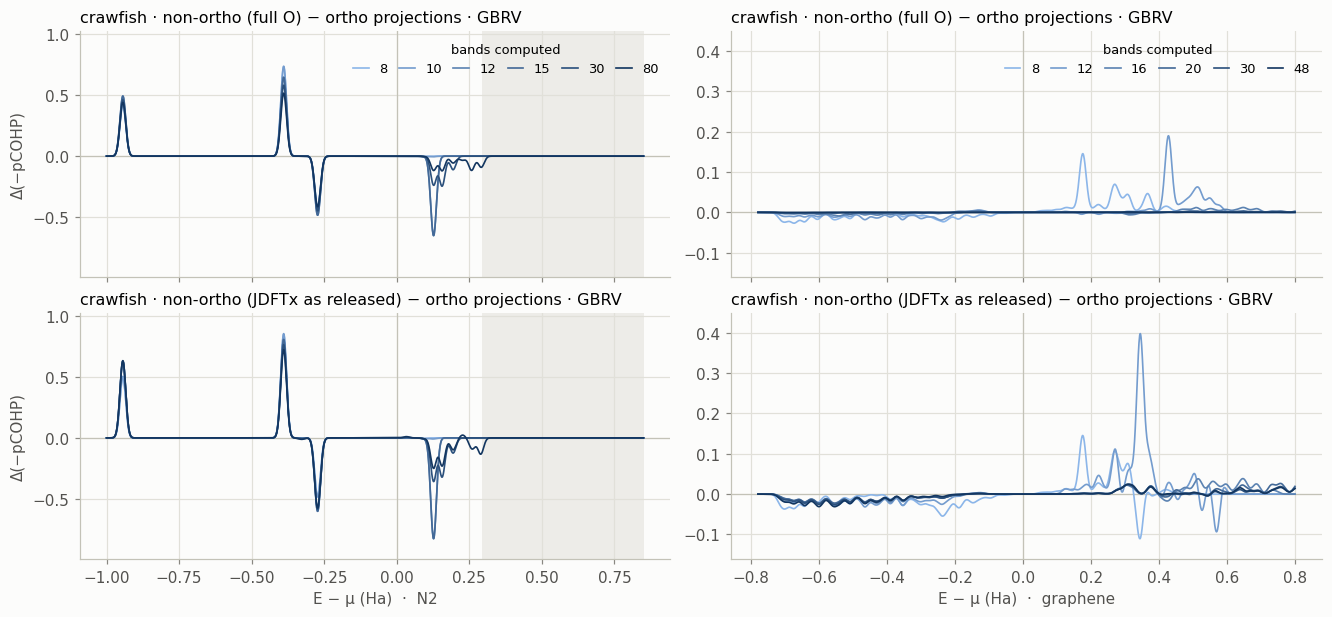

largest change / largest peak of the ortho spectrum:


N2_gbrv                graphene_gbrv               
      nonortho nonortho_jdftx      nonortho nonortho_jdftx
bands                                                     
8       0.0400         0.0464        0.0896         0.0895
10      0.0405         0.0469           NaN            NaN
12      0.0317         0.0403        0.1018         0.2132
15      0.0318         0.0403           NaN            NaN
16         NaN            NaN        0.0065         0.0206
20         NaN            NaN        0.0024         0.0142
30      0.0278         0.0365        0.0006         0.0140
48         NaN            NaN        0.0005         0.0165
80      0.0238         0.0334           NaN            NaN

In [15]:
proj_change = {}  # largest change / largest peak of the ortho spectrum, per band count
fig, axes = spectrum_grid(2, height=2.3)
for j, mol in enumerate(("N2", "graphene")):
    name = f"{mol}_gbrv"
    ramp = band_ramp("crawfish", mol)
    for i, (key, title) in enumerate((("crawfish, nonortho", "non-ortho (full O) − ortho projections"),
                                      ("crawfish, nonortho_jdftx", "non-ortho (JDFTx as released) − ortho projections"))):
        ax = axes[i, j]
        sp = spectrum_panel(ax, name, f"crawfish · {title} · GBRV")
        for nb, y in sp[key].items():
            ax.plot(sp["x"], -(y - sp["crawfish"][nb]), color=ramp[nb], linewidth=1.1, zorder=2, label=str(nb))
        proj_change[(name, key.split(", ")[1])] = {nb: rel(y, sp["crawfish"][nb]) for nb, y in sp[key].items()}
    axes[0, j].legend(title="bands computed", ncols=len(SPEC[mol]["nbs"]), loc="upper right", frameon=False,
                      handlelength=1.2, columnspacing=0.9, fontsize=8.5, title_fontsize=8.5)
for ax in axes[:, 0]:
    ax.set_ylabel("Δ(−pCOHP)")
fig.savefig(bm.FIGURE_DIR / "01_spectra_projection_type.png", dpi=150, facecolor=bm.SURFACE)
plt.show()
print("largest change / largest peak of the ortho spectrum:")
display(pd.DataFrame(proj_change).sort_index().rename_axis("bands"))

**Reading figure 6.**
- **N2: non-orthogonal projections move weight between the σ levels.** At 15 bands, 2σu goes from −0.034 to
  −0.051 Ha with the full overlap operator, and 3σg from +0.041 to +0.053 Ha, while 2σg changes by 2% (−0.515 to
  −0.527; peak table above). The IpCOHP moves by 1.8%, but single σ peaks move by 30–50%. JDFTx's released
  projections do the same, slightly more. The curves for different band counts have the same shape, so this does
  not go away with more bands.
- **Graphene with the full overlap operator: the difference vanishes from 16 bands on** (below 1% of the largest
  peak). It is large only at 8 and 12 bands, in the empty states.
- **Graphene with JDFTx's released projections: the difference stays at every band count.** There is a small,
  uniform weakening of the σ bonding region (occupied σ −0.439 against −0.446 Ha at 20 bands) and changes in the
  empty states. This is the single-centre `OpsiRadial` error of section 8, and more bands don't remove it.

### Figure 7: the band-independent bases, JDFTx `wannier`, and LOBSTER

- **Row 1:** crawfish at all computed bands against the two limits (GBRV).
- **Row 2:** JDFTx `wannier`, projection-only and MLWF, with the complete frozen-window basis for reference
  (GBRV).
- **Row 3 (SG15):**
  - LOBSTER's own `COHPCAR.lobster` (8 bands), broadened further to the same Gaussian;
  - approach 1 at 8 bands without the eigenvalue cutoff (the pure polar factor, float64; section 4);
  - exact-Löwdin.

Gray: above the highest computed band.

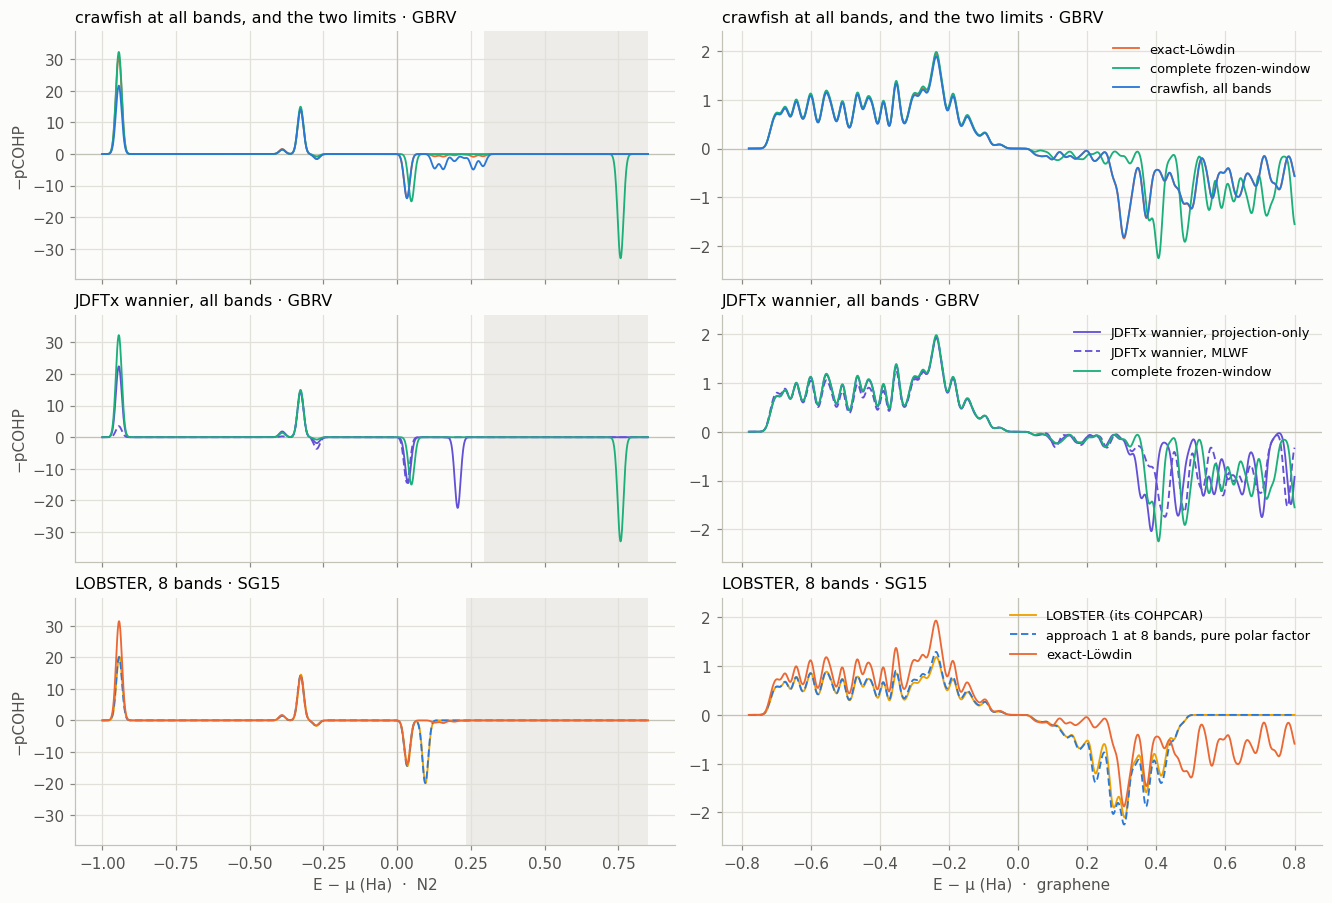

LOBSTER against approach 1 at 8 bands (pure polar factor), largest difference / largest peak: {'N2_sg15': 0.057, 'graphene_sg15': 0.131}


In [16]:
ROWS7 = (("gbrv", "crawfish at all bands, and the two limits · GBRV",
          (("exact-Löwdin", "exact-Löwdin", "exact-Löwdin", "-"),
           ("complete frozen-window", "complete frozen-window", "complete frozen-window", "-"),
           ("crawfish", "crawfish, all bands", "crawfish", "-"))),  # drawn last: in graphene it lies on the limits
         ("gbrv", "JDFTx wannier, all bands · GBRV",
          (("JDFTx projection-only", "JDFTx wannier, projection-only", "JDFTx wannier", "-"),
           ("MLWF", "JDFTx wannier, MLWF", "JDFTx wannier", DASH),
           ("complete frozen-window", "complete frozen-window", "complete frozen-window", "-"))),
         ("sg15", "LOBSTER, 8 bands · SG15",
          (("LOBSTER", "LOBSTER (its COHPCAR)", "LOBSTER", "-"),
           ("polar factor, 8 bands", "approach 1 at 8 bands, pure polar factor", "crawfish", DASH),
           ("exact-Löwdin", "exact-Löwdin", "exact-Löwdin", "-"))))
fig, axes = spectrum_grid(len(ROWS7), height=2.4)
for j, mol in enumerate(("N2", "graphene")):
    for i, (psp, title, curves) in enumerate(ROWS7):
        ax = axes[i, j]
        sp = spectrum_panel(ax, f"{mol}_{psp}", title)
        for key, label, color, ls in curves:
            y = sp[key][max(sp[key])] if isinstance(sp[key], dict) else sp[key]  # crawfish: all bands
            ax.plot(sp["x"], -y, color=bm.COLORS[color], linewidth=1.2, linestyle=ls, label=label, zorder=2)
        if j == 1:
            ax.legend(loc="upper right", frameon=False, fontsize=8.5)
fig.savefig(bm.FIGURE_DIR / "01_spectra_band_independent.png", dpi=150, facecolor=bm.SURFACE)
plt.show()
lobster_vs_polar = {name: rel(sp["LOBSTER"], sp["polar factor, 8 bands"]) for name, sp in spectra.items()
                    if "LOBSTER" in sp}
print("LOBSTER against approach 1 at 8 bands (pure polar factor), largest difference / largest peak:",
      {k: round(float(v), 3) for k, v in lobster_vs_polar.items()})

**Reading figure 7.**
- **Row 1: both limits have a much taller 2σg peak than crawfish** (−0.78 and −0.81 Ha against −0.54; N2 table).
  Below μ the limits are close to each other, and in graphene all three curves are close. Above μ they differ in
  where the antibonding weight sits:
  - complete frozen-window: in a few Ritz states (N2: π\* at +0.05 Ha and σ\* at +0.76 Ha);
  - exact-Löwdin: spread over the computed bands and beyond them;
  - crawfish: in the computed box states, as much as the sum rule requires.
- **Row 2: JDFTx's projection-only `wannier` looks like crawfish at all bands below μ** (its 2σg is as short). Its
  virtual directions condense into one N2 σ\* level near +0.2 Ha, inside the computed box states. **MLWF removes
  almost all of the 2σg peak**, which is the lost σ bond of section 7. In graphene, MLWF follows the
  projection-only spectrum below μ.
- **Row 3: LOBSTER's spectrum is approach 1 at 8 bands.** Its COHPCAR follows the pure-polar-factor spectrum
  peak for peak. The largest difference is 6% of the largest peak for N2 and 13% for graphene (printed above);
  LOBSTER's basis is a Slater fit to the SG15 orbitals, not the orbitals themselves. Its spectrum ends at the 8th
  band:
  - N2: a single box state at +0.09 Ha stands in for σ\*;
  - graphene: there is nothing above +0.5 Ha.

  Its occupied peaks are as short as crawfish's at 8 bands.

## Summary

In [17]:
summary = {}
for name, s in SYSTEMS.items():
    c = series[name]["crawfish"]
    summary[name] = {
        f"crawfish, fixture bands": c[s.nbands_fixture],
        "crawfish, all bands": c[s.nbands_series[-1]],
        "LOBSTER (SG15-fitted basis)": limits[name].get("LOBSTER", np.nan),
        "frozen-window PWF, all bands": series[name]["frozen-window PWF"][s.nbands_series[-1]],
        "JDFTx MLWF, all bands": limits[name].get("MLWF", np.nan),
        "exact-Löwdin": limits[name]["exact-Löwdin"],
        "complete frozen-window": limits[name]["complete frozen-window"],
    }
summary = pd.DataFrame(summary)
display(summary)
display((100 * (summary / summary.loc["complete frozen-window"] - 1)).round(1)
        .style.set_caption("% relative to the complete frozen-window basis"))

,N2_gbrv,N2_sg15,graphene_gbrv,graphene_sg15
"crawfish, fixture bands",-0.8655,-0.8681,-0.5013,-0.4996
"crawfish, all bands",-0.8918,-0.8762,-0.5288,-0.5261
LOBSTER (SG15-fitted basis),NaN,-0.8567,NaN,-0.3766
"frozen-window PWF, all bands",-0.9134,-0.8906,-0.5423,-0.5396
"JDFTx MLWF, all bands",-0.3636,NaN,-0.5193,NaN
exact-Löwdin,-1.1299,-1.1420,-0.5381,-0.5456
complete frozen-window,-1.2029,-1.2134,-0.5530,-0.5610


,N2_gbrv,N2_sg15,graphene_gbrv,graphene_sg15
"crawfish, fixture bands",-28.000000,-28.500000,-9.400000,-10.900000
"crawfish, all bands",-25.900000,-27.800000,-4.400000,-6.200000
LOBSTER (SG15-fitted basis),nan,-29.400000,nan,-32.900000
"frozen-window PWF, all bands",-24.100000,-26.600000,-1.900000,-3.800000
"JDFTx MLWF, all bands",-69.800000,nan,-6.100000,nan
exact-Löwdin,-6.100000,-5.900000,-2.700000,-2.700000
complete frozen-window,0.000000,0.000000,0.000000,0.000000


**For JDFTx setups meant for crawfish:**
- **With crawfish as it is (approach 1), IpCOHP depends on `elec-n-bands`.** In a cell with vacuum it is not
  converged at any practical band count. Compare bonds only at the same band count, cell, pseudopotential and
  projection type, and treat absolute values as lower bounds on the bond strength.
- **crawfish's too-few-bands warning catches only the ill-conditioned extreme** (here N2 at ≤ 10 bands and
  graphene at ≤ 20), not this slow convergence. Results at band counts that trigger it also depend on the energy
  zero (`norm_eigs_for_h`; section 1).
- **To see why a value has not converged, look at the spectrum above μ.** In crawfish's basis the bonding and
  antibonding weights of the computed bands cancel (section 10). A bonding peak whose antibonding partner lies
  above the computed bands stays short:
  - it grows as those states are computed (graphene σ);
  - it never converges if the partner is spread over vacuum states (N2 2σg).

  Per-level weights or channel splits show which peak that is.
- **The pseudopotential family (GBRV vs SG15) changes IpCOHP by ≤ 1.5%** and does not change the convergence.
- **Orthonormalized-orbital projections (`band-projection-params yes no`) are the safer input for pCOHP,**
  especially with ultrasoft pseudopotentials.
- **Band-independent numbers need the exact atomic-orbital matrices** (`jdftx_patch/`). The complete frozen-window
  basis then needs only the occupied bands, plus enough margin to hold the frozen window.

In [18]:
# Checks: each line is a claim made above.
for name, s in SYSTEMS.items():
    c = series[name]["crawfish"]
    assert c[s.nbands_series[-1]] < c[s.nbands_fixture]  # more bands: stronger bond (not monotonic in between)
    assert limits[name]["exact-Löwdin"] < c[s.nbands_series[-1]]  # and still short of its limit
    assert rows[name]["spilling, complete FW (%)"] < 1e-6 and abs(rows[name]["sum-rule miss, complete FW (Ha)"]) < 1e-6
    assert rows[name]["spilling, exact-Löwdin (%)"] > 0.5 and rows[name]["sum-rule miss, exact-Löwdin (Ha)"] > 0.05
    co = calc[name]["ortho"]
    for nb in series[name]["frozen-window PWF"]:  # band-space frozen-window basis: sum rule at every band count
        # (exact up to the Fermi tail above the frozen window and the conditioning at the smallest band counts)
        assert abs(bm.sum_rule_miss(bm.frozen_window_pwf(co, s.e_frozen, nb), co)) < 1e-4
for mol in ("N2", "graphene"):  # pseudopotential family: <= 1.5% in every band-independent basis
    for key in ("exact-Löwdin", "complete frozen-window"):
        a, b = limits[f"{mol}_gbrv"][key], limits[f"{mol}_sg15"][key]
        assert abs(a / b - 1) < 0.015, (mol, key, a, b)
for name, r in lob_rows.items():  # LOBSTER = approach 1 at N_AO bands, up to the regularization of the null direction
    lo = min(v for k, v in r.items() if k.startswith(("singular", "approach 1")))
    hi = max(v for k, v in r.items() if k.startswith(("singular", "approach 1")))
    assert lo - 0.005 <= r["LOBSTER, SG15-fitted basis"] <= hi + 0.005, (name, r)
    lob, pred = (np.array(x.split(" / "), float) for x in (r["LOBSTER total / charge spilling (%)"],
                                                         r["same, predicted from T (%)"]))
    assert np.all(np.abs(lob - pred) < 0.05), (name, lob, pred)
assert limits["N2_gbrv"]["MLWF"] > -0.4 > series["N2_gbrv"]["crawfish"][80]  # MLWF loses N2's sigma bond
assert abs(limits["N2_gbrv"]["JDFTx projection-only"] - (-0.926)) < 2e-3  # JDFTx wannier, nIterations 0

# section 10: spectra
for name, s in SYSTEMS.items():  # sum rule: the pair weights of the computed bands cancel, unless a direction dropped
    co = calc[name]["ortho"]
    for nb in s.nbands_series:
        total = bm.bond_weights_tj(bm.crawfish_basis(co, nb), co).sum()
        assert (abs(total) < 1e-8) == (bm.n_dropped_states(co, nb) == 0), (name, nb, total)
p, g = n2_peaks, gr_peaks
gap = p["exact-Löwdin"] - p["crawfish 80"]
assert abs(gap["2σg"]) > 0.9 * abs(gap["occupied (= IpCOHP)"])  # 2sigma_g carries the N2 shortfall
for nb in SPEC["N2"]["nbs"]:  # the other occupied levels are converged at 8 bands
    for lev in ("2σu", "1πu", "3σg"):
        assert abs(p[f"crawfish {nb}"][lev] - p["crawfish 80"][lev]) < 0.01, (nb, lev)
assert abs(p["crawfish 8"]["higher empty states"]) < 1e-3 and p["crawfish 8"]["sum over the rows"] < -0.4
assert all(0.5 < p[f"crawfish {nb}"]["higher empty states"] < 0.55 for nb in (12, 15, 30, 80))
assert p["exact-Löwdin"]["higher empty states"] < 0.1 and p["exact-Löwdin"]["sum over the rows"] < -0.6
co, cn = calc["N2_gbrv"]["ortho"], calc["N2_gbrv"]["nonortho"]
fw = bm.ritz_states(bm.complete_frozen_window(cn, *ao["N2_gbrv"], SYSTEMS["N2_gbrv"].e_frozen), co)
assert fw.e_tj[0, 7] - co.mu > 0.7 and p["complete frozen-window"]["higher empty states"] > 0.8  # one sigma* state
fw80 = bm.bond_weights_tj(bm.frozen_window_pwf(co, SYSTEMS["N2_gbrv"].e_frozen, 80), co)[0, 0]
assert abs(fw80 / p["crawfish 80"]["2σg"] - 1) < 0.05  # band-space frozen window: 2sigma_g as short as crawfish's
for lev, factor in (("2σu", 1.3), ("3σg", 1.2)):  # non-ortho projections move N2's sigma weight
    for proj in ("full O", "JDFTx"):
        assert p[f"crawfish 15, non-ortho ({proj})"][lev] / p["crawfish 15"][lev] > factor, (lev, proj)
for nb in SPEC["graphene"]["nbs"][1:]:  # graphene: pi converged from 12 bands on; sigma grows
    assert abs(g[f"crawfish {nb}"]["occupied π (pz–pz)"] / g["exact-Löwdin"]["occupied π (pz–pz)"] - 1) < 0.05
sig = [g[f"crawfish {nb}"]["occupied σ"] for nb in SPEC["graphene"]["nbs"]]
assert all(np.diff(sig) < 0) and sig[-1] > g["exact-Löwdin"]["occupied σ"]
assert g["crawfish 12"][["empty, +0.6 to +0.8 Ha", "empty, above +0.8 Ha"]].abs().max() < 1e-3
assert g["crawfish 48"]["empty, above +0.8 Ha"] > 0.1
for nb in (16, 20, 30, 48):  # graphene: full-O projections agree with ortho; JDFTx's released ones do not
    assert proj_change[("graphene_gbrv", "nonortho")][nb] < 0.01 < proj_change[("graphene_gbrv", "nonortho_jdftx")][nb]
for name, v in lobster_vs_polar.items():  # LOBSTER's COHPCAR is approach 1 at 8 bands
    assert v < 0.15, (name, v)
    x, y = spectra[name]["x"], spectra[name]["LOBSTER"]
    assert abs(np.trapezoid(y[x <= 0], x[x <= 0]) - bm.lobster_bond_icohp(name)) < 2e-3  # and integrates to ICOHPLIST
print("all checks passed")

all checks passed
